# High School: five-fold ROC-AUC for W/p × differ/share

Read mode-specific results from the new `summary.npz` format and evaluate the same test hyperedges. The two legacy W results are also supported.

Evaluate saved models without retraining. Score each order separately; aggregate AUC weights orders by positive test-hyperedge counts. Average seeds within each fold before computing the five-fold mean and sample standard deviation.

## Published plotting inputs

Run this notebook from the extracted repository root. The original cross-validation summaries, five held-out test folds, 160 CV fit files, 32 full-data fit files, and small processed High School inputs needed by these plots are bundled under `plot_data/realdata/`. Their values are unchanged; source hashes are listed in `SOURCE.json`. All plots and tables below are recomputed from those inputs without refitting. Output is written under `outputs/`.

Original absolute paths inside saved experiment metadata are provenance only. Runtime lookup uses the local archived fit copies beside each summary. The input metadata retains the original dataset reference; see `plot_data/realdata/SOURCE.json`.


## 1. Paths and filters

Fill in `SUMMARY_FILES` (one or more `summary.npz` files) and `CV_ROOT` (the five-fold test directory), then run from the beginning. Files may contain separately trained modes, provided test data and other settings agree. `PROJECT_DIR` is needed only to verify legacy raw files.

In [1]:
from pathlib import Path
from collections import defaultdict
from datetime import datetime, timezone, timedelta
from typing import Any
import hashlib
import json
import os
import re
import tempfile

# Five-fold result paths; Section 7 configures full-data fits separately.
PROJECT_DIR = Path.cwd().resolve()
PLOT_DATA_DIR = PROJECT_DIR / "plot_data" / "realdata"
SUMMARY_FILES = [str(PLOT_DATA_DIR / "high_school_cv5/W_compare/summary/summary.npz")]  # Required: e.g. [r".../run_ID/summary/summary.npz"]; multiple files are supported.
CV_ROOT = PLOT_DATA_DIR / "high_school_cv5"  # Required: five-fold test directory, e.g. r".../high_school_cv5".
# Run the notebook from the checkout root; all plotting inputs ship in plot_data/.

# Optional: map model names to files when evaluating only the two legacy results.
# Example: {"diffc": r".../final_results_train_batch_W_diffc.npz", "samec": r".../final_results_train_batch_W_samec.npz"}
LEGACY_SUMMARY_FILES = {}
if CV_ROOT is None or not (SUMMARY_FILES or LEGACY_SUMMARY_FILES):
    raise ValueError("请先填写SUMMARY_FILES和CV_ROOT，再从头运行。旧版结果可改填LEGACY_SUMMARY_FILES。")
PROJECT_DIR = (Path.cwd() if PROJECT_DIR is None else Path(PROJECT_DIR)).expanduser().resolve()
CV_ROOT = Path(CV_ROOT).expanduser().resolve()

# Older SciPy versions on Windows may fail with Chinese characters in the system temporary path.
# Set a project-local temporary directory before importing SciPy, replacing the original hardcoded D:/loop_SBM path.
if os.name == "nt":
    scipy_tmp = PROJECT_DIR / ".scipy_tmp"
    scipy_tmp.mkdir(parents=True, exist_ok=True)
    for name in ("TEMP", "TMP", "TMPDIR"):
        os.environ[name] = str(scipy_tmp)
    tempfile.tempdir = str(scipy_tmp)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import rankdata
from IPython.display import display

# None evaluates all modes, seeds, and order sets in the summary files.
# To compare shared models only: MODES_TO_EVALUATE = ["w-share", "p-share"]
MODES_TO_EVALUATE = None
SEEDS_TO_EVALUATE = None
ORDER_SETS_TO_EVALUATE = None

# Usually unnecessary. If a legacy file lacks affinity-order metadata and its raw NPZ is unavailable,
# specify the verified matrix order manually, with a separate mapping for each order set.
AFFINITY_ORDERS_OVERRIDE = None
SHOW_AUC_TABLES = False  # The complete table is still exported as CSV.
SAVE_AUC_OUTPUTS = True
AUC_OUTPUT_DIR = PROJECT_DIR / "outputs" / "realdata_auc"  # Keep generated plots outside bundled inputs.

MODE_LABELS = {
    "w-differ": "W: order-specific", "w-share": "W: shared shape",
    "p-differ": "p: order-specific", "p-share": "p: shared matrix",
    "diffc": "Legacy: order-specific", "samec": "Legacy: shared",
}

def resolve_result_files():
    if SUMMARY_FILES:
        paths = [Path(p).expanduser().resolve() for p in SUMMARY_FILES]
        missing = [str(p) for p in paths if not p.is_file()]
        if missing:
            raise FileNotFoundError("以下汇总不存在：\n" + "\n".join(missing))
        return paths, None
    if LEGACY_SUMMARY_FILES:
        legacy = {model:Path(p).expanduser().resolve() for model,p in LEGACY_SUMMARY_FILES.items()}
        missing = [str(p) for p in legacy.values() if not p.is_file()]
        if missing:
            raise FileNotFoundError("以下旧版汇总不存在：\n" + "\n".join(missing))
        print("本次明确评价旧版结果：", list(legacy))
        return None, legacy
    raise ValueError("请先填写SUMMARY_FILES，或填写旧版LEGACY_SUMMARY_FILES。")

SUMMARY_PATHS, LEGACY_FILES = resolve_result_files()
print("项目：", PROJECT_DIR)
print("测试集：", CV_ROOT)
print("本次输入：", SUMMARY_PATHS if SUMMARY_PATHS else LEGACY_FILES)


项目： D:\codex_data\2026-10-19\wo\outputs\D-HySBM-GitHub
测试集： D:\codex_data\2026-10-19\wo\outputs\D-HySBM-GitHub\plot_data\realdata\high_school_cv5
本次输入： [WindowsPath('D:/codex_data/2026-10-19/wo/outputs/D-HySBM-GitHub/plot_data/realdata/high_school_cv5/W_compare/summary/summary.npz')]


## 2. Scoring and ROC-AUC functions

For each order $d$, use saved node marginals $q_i$ and affinity $p_d$ to compute

$$s(e)=\frac{1}{\binom{d}{2}}\sum_{i<j\in e}q_i^\top p_d q_j.$$

This is a ranking score, rather than a calibrated hyperedge-existence probability. A common positive normalization factor does not affect within-order ROC-AUC. Scores from different orders are not ranked together.

ROC-AUC uses ascending average ranks for ties; identical scores give $0.5$.

In [2]:
def roc_auc(y_true: np.ndarray, scores: np.ndarray) -> float:
    """Mann--Whitney ROC AUC; tied positive/negative scores count as one half."""
    labels = np.asarray(y_true)
    values = np.asarray(scores, dtype=float)
    if labels.ndim != 1 or values.shape != labels.shape:
        raise ValueError("Labels and scores must be equally sized 1D arrays.")
    if not np.all(np.isin(labels, [0, 1])):
        raise ValueError("Labels must contain only 0 and 1.")
    if not np.all(np.isfinite(values)):
        raise ValueError("Scores must be finite.")
    positive = labels == 1
    n_positive = int(positive.sum())
    n_negative = len(labels) - n_positive
    if not n_positive or not n_negative:
        raise ValueError("ROC AUC requires at least one positive and one negative.")
    ranks = rankdata(values, method="average")
    numerator = ranks[positive].sum() - n_positive * (n_positive + 1) / 2
    return float(numerator / (n_positive * n_negative))


def _integer(value: Any, name: str) -> int:
    array = np.asarray(value)
    if array.size != 1:
        raise ValueError(f"{name} must be a scalar integer.")
    item = array.reshape(-1)[0]
    try:
        result = int(item)
    except (TypeError, ValueError, OverflowError) as error:
        raise ValueError(f"{name} must be an integer.") from error
    if isinstance(item, (str, np.str_)):
        valid = str(result) == item
    else:
        valid = not isinstance(item, (bool, np.bool_)) and item == result
    if not valid:
        raise ValueError(f"{name} must be an integer.")
    return result


def normalized_marginals(log_marginals: np.ndarray) -> np.ndarray:
    logs = np.asarray(log_marginals, dtype=float)
    if logs.ndim != 2 or min(logs.shape) < 1:
        raise ValueError("log_marginals must have shape (N, K), with N,K positive.")
    if np.any(np.isnan(logs)) or np.any(np.isposinf(logs)):
        raise ValueError("log_marginals cannot contain NaN or positive infinity.")
    row_max = np.max(logs, axis=1, keepdims=True)
    if not np.all(np.isfinite(row_max)):
        raise ValueError("Each log_marginals row needs a finite entry.")
    probabilities = np.exp(logs - row_max)
    return probabilities / probabilities.sum(axis=1, keepdims=True)


def affinities_by_order(
    fit: Any, orders: list[int], group_count: int
) -> tuple[dict[int, np.ndarray], str]:
    """Resolve explicit order mappings; never infer array order from test edges."""
    raw = fit["p"]
    if isinstance(raw, np.ndarray) and raw.dtype == object and raw.size == 1:
        candidate = raw.reshape(-1)[0]
        if isinstance(candidate, dict):
            raw = candidate

    if isinstance(raw, dict):
        mapped: dict[int, np.ndarray] = {}
        for key, value in raw.items():
            order = _integer(key, "p dictionary key")
            if order < 2 or order in mapped:
                raise ValueError("p dictionary requires unique orders >= 2.")
            mapped[order] = np.asarray(value, dtype=float)
        affinity_kind = "order-specific dictionary"
    else:
        values = np.asarray(raw, dtype=float)
        if values.ndim == 2:
            mapped = {order: values for order in orders}
            affinity_kind = "shared 2D affinity applied to every requested order"
        elif values.ndim == 3:
            if "selected_hye_sizes" not in fit:
                raise ValueError(
                    "A 3D p array requires selected_hye_sizes in the fit NPZ; "
                    "the order mapping cannot be guessed."
                )
            size_array = np.asarray(fit["selected_hye_sizes"]).reshape(-1)
            sizes = [_integer(size, "selected_hye_sizes entry") for size in size_array]
            if len(sizes) != values.shape[0] or len(set(sizes)) != len(sizes):
                raise ValueError("selected_hye_sizes must map each p matrix exactly once.")
            if any(size < 2 for size in sizes):
                raise ValueError("selected_hye_sizes entries must be >= 2.")
            mapped = dict(zip(sizes, values))
            affinity_kind = "order-specific array with explicit selected_hye_sizes"
        else:
            raise ValueError("p must be a 2D matrix, a 3D array, or an order-keyed dict.")

    missing = sorted(set(orders) - mapped.keys())
    if missing:
        raise ValueError(f"Fit has no affinity for requested test orders {missing}.")
    selected: dict[int, np.ndarray] = {}
    for order in orders:
        matrix = mapped[order]
        if matrix.shape != (group_count, group_count):
            raise ValueError(f"Order {order}: p must have shape ({group_count}, {group_count}).")
        if not np.all(np.isfinite(matrix)) or np.any(matrix < 0):
            raise ValueError(f"Order {order}: affinities must be finite and nonnegative.")
        if not np.allclose(matrix, matrix.T, rtol=1e-7, atol=1e-12):
            raise ValueError(f"Order {order}: affinity must be symmetric.")
        selected[order] = matrix
    return selected, affinity_kind


## 3. Load summaries, verify affinity order, and evaluate five folds

Derive fold numbers from `high_school_train0`–`train4`, rather than list positions. Prefer explicit matrix-order metadata; verify legacy ordering against local raw NPZ files to avoid confusing second- and third-order matrices. Missing folds, duplicates, and mismatched matrices raise errors.

In [3]:
# This cell is deliberately self contained. The scoring helpers in cell 4 are reused.
from collections import defaultdict
from pathlib import Path
import hashlib
import json
import re
import numpy as np


_AUC_MODES = {
    'w-differ': ('paper-w', 'differ'), 'w-share': ('paper-w', 'share'),
    'p-differ': ('direct-p', 'differ'), 'p-share': ('direct-p', 'share'),
}


def _auc_orders(value, name='orders'):
    raw = np.asarray(value)
    if raw.ndim != 1 or raw.size == 0:
        raise ValueError(f'{name} must be a nonempty one-dimensional integer sequence.')
    result = tuple(_integer(d, name) for d in raw)
    if min(result) < 2 or len(set(result)) != len(result):
        raise ValueError(f'{name} must contain distinct integers >= 2.')
    return result


def _auc_paths(value):
    if value is None:
        return []
    if isinstance(value, (str, Path)):
        return [Path(value)]
    return [Path(p) for p in value]


def _auc_hash(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()


def load_tests(cv_root):
    """Load the fixed five folds; accept either fold_XX subfolders or flat files."""
    cv_root = Path(cv_root)
    tests, provenance, all_positives = {}, {}, set()
    for fold in range(5):
        candidates = [cv_root / f'fold_{fold:02d}' / f'high_school_test{fold}.npz',
                      cv_root / f'high_school_test{fold}.npz']
        existing = [p for p in candidates if p.is_file()]
        if not existing:
            raise FileNotFoundError(f'Missing fold-{fold} test file under {cv_root}.')
        if len(existing) > 1 and len({_auc_hash(p) for p in existing}) != 1:
            raise ValueError(f'Conflicting flat/nested fold-{fold} test files under {cv_root}.')
        path = existing[0]
        with np.load(path, allow_pickle=True) as data:
            if _integer(data['fold'], 'test fold') != fold:
                raise ValueError(f'Fold mismatch: {path}')
            N = _integer(data['N'], 'test N')
            if N < 1:
                raise ValueError(f'Invalid node count: {path}')
            labels, sizes = np.asarray(data['y_true']), np.asarray(data['edge_sizes'])
            raw_edges = data['hyperedges']
            if (labels.ndim != 1 or labels.shape != raw_edges.shape or sizes.shape != labels.shape
                    or not np.isin(labels, [0, 1]).all()):
                raise ValueError(f'Inconsistent test arrays or labels: {path}')
            checked_sizes = np.array([_integer(d, 'test edge size') for d in sizes])
            edges = []
            for raw, size in zip(raw_edges, checked_sizes):
                nodes = np.asarray(raw)
                if nodes.ndim != 1 or not np.issubdtype(nodes.dtype, np.integer):
                    raise ValueError(f'Invalid node IDs: {path}')
                edge = tuple(sorted(int(v) for v in nodes))
                if len(edge) != size or size < 2 or len(set(edge)) != size:
                    raise ValueError(f'Invalid hyperedge: {path}')
                if edge[0] < 0 or edge[-1] >= N:
                    raise ValueError(f'Node ID out of range: {path}')
                edges.append(edge)
        positives = {e for e, y in zip(edges, labels) if y == 1}
        if len(set(edges)) != len(edges) or positives & all_positives:
            raise ValueError('Duplicate test edges or overlapping positive test folds.')
        all_positives.update(positives)
        tests[fold] = dict(N=N, edges=edges, labels=labels, sizes=checked_sizes)
        provenance[str(fold)] = dict(file=str(path.resolve()), sha256=_auc_hash(path))
    if len({t['N'] for t in tests.values()}) != 1:
        raise ValueError('All test folds must use the same node numbering and node count.')
    for test in tests.values():
        if {e for e, y in zip(test['edges'], test['labels']) if y == 0} & all_positives:
            raise ValueError('A sampled negative appears in the observed positive set.')
    return tests, provenance


def _auc_raw_candidates(case, summary_path, project_dir, search_cache):
    """Resolve archived fit copies beside the selected summary, never old absolute paths."""
    summary_path = Path(summary_path)
    run_root = summary_path.parent.parent if summary_path.parent.name == 'summary' else summary_path.parent
    direct = []
    if case.get('mode') in _AUC_MODES and 'idx_sizes' in case:
        label = '_'.join(map(str, sorted(case['selected_hye_sizes'])))
        direct.append(run_root / case['mode'] / case['real_dataset'] /
                      f"case_{int(case['idx_sizes']):03d}_sizes_{label}" /
                      f"seed_{case['seed']}" / 'mp_results/inferred_params.npz')
    cache_key = str(run_root.resolve())
    if cache_key not in search_cache:
        search_cache[cache_key] = sorted(run_root.rglob('inferred_params.npz')) if run_root.is_dir() else []
    for path in search_cache[cache_key]:
        if case['real_dataset'] in path.parts:
            direct.append(path)
    seen = set()
    return [p for p in direct if p.is_file() and not (str(p.resolve()) in seen or seen.add(str(p.resolve())))]


def _auc_override(override, case):
    if override is None:
        return None
    if isinstance(override, dict):
        keys = [(case['model'], case['real_dataset'], tuple(case['train_orders']), case['seed']),
                (case['model'], tuple(case['train_orders'])), tuple(case['train_orders'])]
        return next((override[key] for key in keys if key in override), None)
    return override


def _auc_affinity_orders(case, summary_path, project_dir, override, search_cache, raw_cache):
    requested = tuple(case['train_orders'])
    p = np.asarray(case['p'], dtype=float)
    if p.ndim != 3:
        raise ValueError('Saved comparison p must have shape (orders, K, K).')

    def checked(value, source):
        orders = _auc_orders(value, 'affinity_orders')
        if len(orders) != p.shape[0] or set(orders) != set(requested):
            raise ValueError(f'affinity_orders does not map each requested p matrix once: {source}')
        return orders, source

    if case.get('affinity_orders') is not None:
        return checked(case['affinity_orders'], 'explicit affinity_orders in summary')
    explicit = _auc_override(override, case)
    if explicit is not None:
        return checked(explicit, 'explicit user affinity_orders_override')
    matches = {}
    for path in _auc_raw_candidates(case, summary_path, project_dir, search_cache):
        name = str(path.resolve())
        if name not in raw_cache:
            with np.load(path, allow_pickle=True) as raw:
                keys = ('p', 'n', 'log_marginals', 'selected_hye_sizes')
                raw_cache[name] = {k: np.asarray(raw[k]) for k in keys} if all(k in raw for k in keys) else None
        raw = raw_cache[name]
        if raw is None:
            continue
        if not all(np.array_equal(np.asarray(case[k]), raw[k], equal_nan=True)
                   for k in ('p', 'n', 'log_marginals')):
            continue
        orders, _ = checked(raw['selected_hye_sizes'], f'verified raw NPZ {name}')
        matches.setdefault(orders, []).append(name)
    if len(matches) > 1:
        raise ValueError(f"Ambiguous raw affinity order mappings for {case['model']} {case['real_dataset']}: {list(matches)}")
    if matches:
        orders = next(iter(matches))
        return orders, 'verified raw NPZ: ' + matches[orders][0]
    raise ValueError(
        f"Cannot verify affinity order mapping: {case['model']} {case['real_dataset']} "
        f"D={requested}, seed={case['seed']}. Requested selected_hye_sizes is not proof of p order. "
        'Use a summary with explicit affinity_orders, copy the matching raw inferred_params.npz '
        'inside its run/CV folder, or set affinity_orders_override after independently checking the order.'
    )


def _auc_read_sources(summary_files, legacy_files, project_dir, override):
    inputs = [(p, None) for p in _auc_paths(summary_files)]
    if legacy_files is not None:
        if isinstance(legacy_files, dict):
            inputs.extend((Path(path), str(model)) for model, path in legacy_files.items())
        else:
            for path in _auc_paths(legacy_files):
                match = re.fullmatch(r'final_results_train_batch_W_(diffc|samec)\.npz', path.name)
                if match is None:
                    raise ValueError(f'Legacy file requires a model-to-path mapping: {path}')
                inputs.append((path, match.group(1)))
    if not inputs:
        raise ValueError('No summary inputs. Set summary_files or legacy_files explicitly.')
    paths = [str(p.resolve()) for p, _ in inputs]
    if len(set(paths)) != len(paths):
        raise ValueError('Duplicate summary input file.')
    all_cases, source_info = [], {}
    declared = dict(models=set(), seeds=set(), order_sets=set())
    search_cache, raw_cache = {}, {}
    for path, legacy_model in inputs:
        with np.load(path, allow_pickle=True) as data:
            if 'case_results' not in data:
                raise ValueError(f'Summary has no case_results: {path}')
            cases = np.asarray(data['case_results'], dtype=object).reshape(-1).tolist()
            if not cases:
                raise ValueError(f'Empty summary: {path}')
            if not all(isinstance(c, dict) for c in cases):
                raise ValueError(f'case_results must contain dictionaries: {path}')
            top = {k: np.asarray(data[k]) for k in data.files if k in (
                'mode_list', 'seeds', 'seed_mp', 'affinity_orders_list', 'K',
                'mode', 'sharing', 'affinity_update', 'seed', 'real_dataset',
                'selected_hye_sizes_list', 'train_list')}
        protocol_path = path.parent.parent / 'protocol.json' if path.parent.name == 'summary' else path.parent / 'protocol.json'
        configuration = {}
        if protocol_path.is_file():
            configuration = json.loads(protocol_path.read_text(encoding='utf-8')).get('configuration', {})
        file_modes = [str(m) for m in np.asarray(top.get('mode_list', configuration.get('modes', []))).reshape(-1)]
        if not legacy_model and (len(file_modes) != len(set(file_modes)) or set(file_modes) - _AUC_MODES.keys()):
            raise ValueError(f'Invalid declared mode_list in {path}.')
        file_seeds = [_integer(s, 'declared seed') for s in np.asarray(
            top.get('seeds', top.get('seed_mp', configuration.get('seeds', [])))).reshape(-1)]
        if len(file_seeds) != len(set(file_seeds)) or any(s < 0 for s in file_seeds):
            raise ValueError(f'Invalid declared seeds in {path}.')
        file_orders = {tuple(sorted(_auc_orders(s))) for s in configuration.get('order_sets', [])}
        file_datasets = {str(s) for s in np.asarray(top.get('train_list', configuration.get('train_list', []))).reshape(-1)}
        if legacy_model:
            declared['models'].add(legacy_model)
        else:
            declared['models'].update(file_modes)
        declared['seeds'].update(file_seeds)
        declared['order_sets'].update(file_orders)
        source_info[str(path.resolve())] = dict(file=str(path.resolve()), sha256=_auc_hash(path),
                                               kind='legacy' if legacy_model else 'four-mode')
        if protocol_path.is_file():
            source_info[str(path.resolve())]['protocol_file'] = str(protocol_path.resolve())
        for index, original in enumerate(cases):
            case = dict(original)
            if 'real_dataset' not in case and 'dataset' in case:
                case['real_dataset'] = case['dataset']
            dataset = str(case.get('real_dataset', ''))
            if 'dataset' in case and str(case['dataset']) != dataset:
                raise ValueError(f'Conflicting dataset metadata in {path}, case {index}.')
            match = re.fullmatch(r'high_school_train([0-4])', dataset)
            if match is None:
                raise ValueError(f'Unexpected dataset: {dataset}; use high_school_train0 through train4.')
            if file_datasets and dataset not in file_datasets:
                raise ValueError(f'Dataset is absent from declared train_list: {dataset}')
            requested = tuple(sorted(_auc_orders(case['selected_hye_sizes'], 'selected_hye_sizes')))
            if file_orders and requested not in file_orders:
                raise ValueError(f'Orders are absent from declared order_sets: {requested}')
            mode = legacy_model or str(case.get('mode', ''))
            if not legacy_model:
                if mode not in _AUC_MODES:
                    raise ValueError(f'Unknown four-mode metadata: {mode!r}')
                if file_modes and mode not in file_modes:
                    raise ValueError(f'Case mode is absent from declared mode_list: {mode}')
                affinity, sharing = _AUC_MODES[mode]
                for key, expected in [('affinity_update', affinity), ('sharing', sharing)]:
                    if key not in case or str(case[key]) != expected:
                        raise ValueError(f'Conflicting or missing {key} metadata for {mode}.')
                if 'shared_hye_sizes' in case:
                    groups = [tuple(sorted(_auc_orders(group, 'shared_hye_sizes'))) for group in case['shared_hye_sizes']]
                    expected_groups = [requested] if sharing == 'share' else [(d,) for d in requested]
                    if sorted(groups) != sorted(expected_groups):
                        raise ValueError(f'shared_hye_sizes conflicts with {mode} sharing metadata.')
            elif 'mode' in case and str(case['mode']) != mode:
                raise ValueError(f'Conflicting legacy mode metadata for {mode}.')
            seed_value = case.get('seed', top.get('seed_mp'))
            if seed_value is None:
                raise ValueError(f'Missing seed for {mode} {dataset}.')
            seed = _integer(seed_value, 'seed')
            if seed < 0:
                raise ValueError('Seeds must be nonnegative integers.')
            if file_seeds and seed not in file_seeds:
                raise ValueError(f'Case seed is absent from declared seeds: {seed}')
            # Reject contradictory repeated metadata rather than silently choosing one.
            for key, value in [('mode', mode), ('real_dataset', dataset), ('seed', seed),
                               ('affinity_update', case.get('affinity_update')), ('sharing', case.get('sharing'))]:
                if key in top:
                    values = top[key].reshape(-1)
                    if len(values) != len(cases) or str(values[index]) != str(value):
                        raise ValueError(f'Conflicting top-level {key} metadata in {path}.')
            if 'selected_hye_sizes_list' in top:
                if len(top['selected_hye_sizes_list']) != len(cases) or set(_auc_orders(top['selected_hye_sizes_list'][index])) != set(requested):
                    raise ValueError(f'Conflicting selected_hye_sizes_list metadata in {path}.')
            if 'affinity_orders_list' in top:
                if len(top['affinity_orders_list']) != len(cases):
                    raise ValueError(f'affinity_orders_list length mismatch: {path}')
                top_orders = _auc_orders(top['affinity_orders_list'][index], 'affinity_orders_list')
                if 'affinity_orders' in case and top_orders != _auc_orders(case['affinity_orders']):
                    raise ValueError(f'Conflicting affinity_orders metadata in {path}.')
                case['affinity_orders'] = top_orders
            case.update(model=mode, mode=mode, real_dataset=dataset, seed=seed,
                        fold=int(match.group(1)), train_orders=requested, source_file=str(path.resolve()))
            p = np.asarray(case['p'], dtype=float)
            q = normalized_marginals(case['log_marginals'])
            if p.ndim != 3 or p.shape != (len(requested), q.shape[1], q.shape[1]):
                raise ValueError(f'p/marginals dimensions disagree for {mode} {dataset}.')
            if 'K' in top and _integer(top['K'], 'summary K') != q.shape[1]:
                raise ValueError(f'Summary K disagrees with marginals for {mode} {dataset}.')
            if 'n' not in case or np.asarray(case['n']).shape != (q.shape[1],):
                raise ValueError(f'n must have shape (K,) for {mode} {dataset}.')
            case['affinity_orders'], case['affinity_order_source'] = _auc_affinity_orders(
                case, path, project_dir, override, search_cache, raw_cache)
            # Supply the proven order sequence to the unchanged cell-4 helper.
            fit = dict(p=p, selected_hye_sizes=list(case['affinity_orders']))
            case['affinities'], case['affinity_kind'] = affinities_by_order(fit, list(requested), q.shape[1])
            if mode == 'p-share' and not all(np.allclose(m, p[0]) for m in p):
                raise ValueError('p-share must share the same complete p matrix across orders.')
            case['q'] = q
            all_cases.append(case)
            declared['models'].add(mode)
            declared['seeds'].add(seed)
            declared['order_sets'].add(requested)
    return all_cases, declared, source_info


def evaluate_case(case, model, tests):
    """Score one saved fit; mode/seed bookkeeping does not change the score formula."""
    fold, orders = case['fold'], tuple(case['train_orders'])
    q, test = case['q'], tests[fold]
    if len(q) != test['N']:
        raise ValueError(f"Node count mismatch: {case['real_dataset']}")
    rows = []
    for order in orders:
        indices = np.flatnonzero(test['sizes'] == order)
        if not len(indices):
            raise ValueError(f'No order-{order} test edges in fold {fold}.')
        edges = np.asarray([test['edges'][i] for i in indices], dtype=int)
        labels = test['labels'][indices]
        pair_scores = q @ case['affinities'][order] @ q.T
        scores = np.zeros(len(edges), dtype=float)
        for a in range(order):
            for b in range(a + 1, order):
                scores += pair_scores[edges[:, a], edges[:, b]]
        scores /= order * (order - 1) / 2
        rows.append(dict(model=model, mode=model, train_orders=list(orders),
                         dataset=case['real_dataset'], fold=fold, seed=case['seed'], test_order=order,
                         n_positive=int((labels == 1).sum()), n_negative=int((labels == 0).sum()),
                         roc_auc=roc_auc(labels, scores)))
    aucs = np.array([r['roc_auc'] for r in rows])
    weights = np.array([r['n_positive'] for r in rows])
    return rows, dict(model=model, mode=model, train_orders=list(orders), fold=fold,
                      dataset=case['real_dataset'], seed=case['seed'],
                      macro_auc=float(aucs.mean()), weighted_auc=float(np.average(aucs, weights=weights)))


def _auc_group_key(row, keys):
    return tuple(tuple(row[k]) if isinstance(row[k], (list, tuple)) else row[k] for k in keys)


def _auc_average_seeds(rows, keys, metrics, seeds):
    groups = defaultdict(list)
    for row in rows:
        groups[_auc_group_key(row, keys)].append(row)
    output = []
    for key, values in sorted(groups.items()):
        values.sort(key=lambda row: row['seed'])
        if [r['seed'] for r in values] != sorted(seeds):
            raise ValueError(f'Missing or duplicate seeds: {key}')
        result = {k: list(v) if isinstance(v, tuple) else v for k, v in zip(keys, key)}
        result.update(mode=result['model'], seeds=sorted(seeds), n_seeds=len(seeds), dataset=values[0]['dataset'])
        for name in ('n_positive', 'n_negative'):
            if name in values[0]:
                if len({r[name] for r in values}) != 1:
                    raise ValueError(f'Test sample counts differ across seeds: {key}')
                result[name] = values[0][name]
        for metric in metrics:
            result[metric] = float(np.mean([r[metric] for r in values]))
            result[metric + '_seed_values'] = [float(r[metric]) for r in values]
        output.append(result)
    return output


def fold_summary(rows, keys, metrics):
    groups = defaultdict(list)
    for row in rows:
        groups[_auc_group_key(row, keys)].append(row)
    output = []
    for key, values in sorted(groups.items()):
        values.sort(key=lambda row: row['fold'])
        if [r['fold'] for r in values] != list(range(5)):
            raise ValueError(f'Missing or duplicate folds: {key}')
        result = {k: list(v) if isinstance(v, tuple) else v for k, v in zip(keys, key)}
        result['folds'] = list(range(5))
        for metric in metrics:
            numbers = np.array([r[metric] for r in values], dtype=float)
            if not np.isfinite(numbers).all():
                raise ValueError(f'Nonfinite metric: {key} {metric}')
            result[metric + '_fold_values'] = numbers.tolist()
            result[metric + '_mean'] = float(numbers.mean())
            result[metric + '_std'] = float(numbers.std(ddof=1))
        output.append(result)
    return output


def _auc_paired(rows, aggregates, models):
    comparisons = [('w-differ', 'p-differ'), ('w-share', 'p-share'),
                   ('w-share', 'w-differ'), ('p-share', 'p-differ'), ('samec', 'diffc')]
    output = []
    for source, metrics, extra in [(rows, ['roc_auc'], ['test_order']),
                                    (aggregates, ['weighted_auc', 'macro_auc'], [])]:
        lookup = {_auc_group_key(r, ['model', 'train_orders', 'fold'] + extra): r for r in source}
        settings = sorted({_auc_group_key(r, ['train_orders'] + extra) for r in source})
        for left, right in comparisons:
            if left not in models or right not in models:
                continue
            for setting in settings:
                orders, tail = setting[0], setting[1:]
                for metric in metrics:
                    differences = [float(lookup[(left, orders, f) + tail][metric] -
                                         lookup[(right, orders, f) + tail][metric]) for f in range(5)]
                    result = dict(left_model=left, right_model=right, metric=metric,
                                  train_orders=list(orders), folds=list(range(5)),
                                  difference_fold_values=differences,
                                  difference_mean=float(np.mean(differences)),
                                  difference_std=float(np.std(differences, ddof=1)))
                    result.update(zip(extra, tail))
                    output.append(result)
    return output


def evaluate_batch(summary_files=None, cv_root=None, legacy_files=None, modes=None,
                   seeds=None, order_sets=None, project_dir=None, affinity_orders_override=None):
    """Evaluate saved summaries; average seeds within folds and never select fits by AUC.

    affinity_orders_override is an explicit, user-verified matrix order sequence, or
    a dictionary keyed by (model,dataset,orders_tuple,seed), (model,orders_tuple),
    or orders_tuple. It is only used when explicit saved affinity_orders is absent.
    """
    project_dir = Path(project_dir or globals().get('PROJECT_DIR', Path.cwd()))
    cv_root = Path(cv_root or globals().get('CV_ROOT', project_dir / 'data/processed_input/high_school_cv5'))
    if summary_files is None:
        summary_files = globals().get('SUMMARY_FILES', [])
    if not _auc_paths(summary_files) and legacy_files is None:
        legacy_files = globals().get('LEGACY_FILES')
        if legacy_files is None:
            legacy_root = Path(globals().get('BATCH_ROOT', cv_root))
            legacy_files = {m: legacy_root / f'final_results_train_batch_W_{m}.npz' for m in ('diffc', 'samec')}
    tests, test_files = load_tests(cv_root)
    cases, declared, sources = _auc_read_sources(summary_files, legacy_files, project_dir,
                                                affinity_orders_override)
    models = list(modes) if modes is not None else [m for m in (*_AUC_MODES, 'diffc', 'samec') if m in declared['models']]
    chosen_seeds = sorted(_integer(s, 'requested seed') for s in seeds) if seeds is not None else sorted(declared['seeds'])
    chosen_orders = [tuple(sorted(_auc_orders(s))) for s in order_sets] if order_sets is not None else sorted(declared['order_sets'], key=lambda s: (len(s), s))
    if (not models or len(set(models)) != len(models) or set(models) - declared['models']):
        raise ValueError('Requested modes are empty, duplicate, or absent from the declared inputs.')
    if (not chosen_seeds or len(set(chosen_seeds)) != len(chosen_seeds) or set(chosen_seeds) - declared['seeds']):
        raise ValueError('Requested seeds are empty, duplicate, or absent from the declared inputs.')
    if (not chosen_orders or len(set(chosen_orders)) != len(chosen_orders) or set(chosen_orders) - declared['order_sets']):
        raise ValueError('Requested order_sets are empty, duplicate, or absent from the declared inputs.')
    cases = [c for c in cases if c['model'] in models and c['seed'] in chosen_seeds and tuple(c['train_orders']) in chosen_orders]
    expected = {(m, f, o, s) for m in models for f in range(5) for o in chosen_orders for s in chosen_seeds}
    seen = set()
    for case in cases:
        key = (case['model'], case['fold'], tuple(case['train_orders']), case['seed'])
        if key in seen:
            raise ValueError(f'Duplicate fit: {key}')
        seen.add(key)
    if seen != expected:
        raise ValueError(f'Incomplete batch: missing {sorted(expected - seen)}; unexpected {sorted(seen - expected)}')
    cases.sort(key=lambda c: (models.index(c['model']), chosen_orders.index(tuple(c['train_orders'])), c['fold'], c['seed']))
    per_seed_rows, per_seed_aggregates = [], []
    metadata = []
    for case in cases:
        rows, aggregate = evaluate_case(case, case['model'], tests)
        per_seed_rows.extend(rows)
        per_seed_aggregates.append(aggregate)
        metadata.append(dict(model=case['model'], mode=case['model'], dataset=case['real_dataset'],
                             fold=case['fold'], seed=case['seed'], train_orders=list(case['train_orders']),
                             affinity_orders=list(case['affinity_orders']),
                             affinity_order_source=case['affinity_order_source'], source_file=case['source_file']))
    rows = _auc_average_seeds(per_seed_rows, ['model', 'train_orders', 'fold', 'test_order'], ['roc_auc'], chosen_seeds)
    aggregates = _auc_average_seeds(per_seed_aggregates, ['model', 'train_orders', 'fold'], ['macro_auc', 'weighted_auc'], chosen_seeds)
    summary = fold_summary(rows, ['model', 'train_orders', 'test_order'], ['roc_auc'])
    return dict(
        score='mean over node pairs of q_i.T @ p_d @ q_j; ranking score, not calibrated probability',
        notes=[
            'Identical order-2 held-out edges are used for the main comparison across configurations.',
            'AUC is computed within each order; different orders are never pooled into one ranking.',
            'weighted_auc uses each order\'s positive test count within a fold; macro_auc weights orders equally.',
            'For multiple seeds, metrics are averaged within each fold before five-fold mean and sample SD.',
            'The five-fold SD uses ddof=1; it is descriptive, not a confidence interval.',
            'Different train_orders imply different test-order mixtures in macro/weighted results.',
            'Every declared/requested mode/order/seed requires all five named folds, without duplicates.',
            'No fit or seed is selected using test AUC; training restarts are not independent test folds.',
            'Order 5 has only 1-2 positive examples per High School fold; interpret descriptively.',
        ],
        models=models, seeds=chosen_seeds, order_sets=[list(s) for s in chosen_orders],
        summary_files=sources, test_files=test_files, normalized_cases=metadata,
        per_seed_fold_per_order=per_seed_rows, per_seed_fold_aggregate=per_seed_aggregates,
        per_seed_order_summary=fold_summary(per_seed_rows, ['model', 'train_orders', 'seed', 'test_order'], ['roc_auc']),
        per_seed_aggregate_summary=fold_summary(per_seed_aggregates, ['model', 'train_orders', 'seed'], ['macro_auc', 'weighted_auc']),
        per_fold_per_order=rows, per_order_summary=summary,
        pairwise_auc_summary=[r for r in summary if r['test_order'] == 2],
        per_fold_aggregate=aggregates,
        aggregate_summary=fold_summary(aggregates, ['model', 'train_orders'], ['macro_auc', 'weighted_auc']),
        paired_comparison=_auc_paired(rows, aggregates, models),
    )


## 4. Compute a common second-order comparison

Evaluate every training configuration on the same second-order test hyperedges. The actual modes, seeds, and order sets determine row counts; the model count is not fixed at 80.

In [4]:
# Evaluate saved parameters without retraining or selecting restarts by test AUC.
auc_report = evaluate_batch(
    summary_files=SUMMARY_PATHS, cv_root=CV_ROOT, legacy_files=LEGACY_FILES,
    modes=MODES_TO_EVALUATE, seeds=SEEDS_TO_EVALUATE,
    order_sets=ORDER_SETS_TO_EVALUATE, project_dir=PROJECT_DIR,
    affinity_orders_override=AFFINITY_ORDERS_OVERRIDE,
)
MODELS = tuple(auc_report["models"])
ORDER_SETS = [tuple(orders) for orders in auc_report["order_sets"]]
SEEDS = auc_report["seeds"]
auc_per_seed_fold = pd.DataFrame(auc_report["per_seed_fold_per_order"])
aggregate_per_seed_fold = pd.DataFrame(auc_report["per_seed_fold_aggregate"])
auc_per_fold = pd.DataFrame(auc_report["per_fold_per_order"])
auc_summary = pd.DataFrame(auc_report["per_order_summary"])
pairwise_summary = pd.DataFrame(auc_report["pairwise_auc_summary"])
aggregate_summary = pd.DataFrame(auc_report["aggregate_summary"])
paired_auc_comparison = pd.DataFrame(auc_report.get("paired_comparison", []))

def order_label(orders):
    return "{" + ",".join(map(str, orders)) + "}"

order_labels = [order_label(orders) for orders in ORDER_SETS]
print("评价模式：", MODELS)
print("种子：", SEEDS)
print("训练结果数：", len(aggregate_per_seed_fold))
print("逐阶AUC数：", len(auc_per_seed_fold))
print("先在每折内平均种子，再报告5折均值±样本标准差(ddof=1)。")
if not pairwise_summary.empty:
    table = pairwise_summary.copy()
    table["D"] = table["train_orders"].map(order_label)
    table["AUC mean ± SD"] = [f"{m:.6f} ± {s:.6f}" for m,s in
                               zip(table["roc_auc_mean"],table["roc_auc_std"])]
    pairwise_table = table.pivot(index="D", columns="model", values="AUC mean ± SD").reindex(
        index=order_labels, columns=list(MODELS))
    if SHOW_AUC_TABLES:
        display(pairwise_table)
else:
    print("所选配置不包含二阶；可在后续表格查看其他测试阶或综合AUC。")


评价模式： ('w-differ', 'w-share', 'p-differ', 'p-share')
种子： [234]
训练结果数： 160
逐阶AUC数： 400
先在每折内平均种子，再报告5折均值±样本标准差(ddof=1)。


## 5. Inspect a target order

Display only training configurations containing the target order. `auc_per_fold` retains positive/negative sample counts and AUC per fold; `auc_summary` retains order-specific means, standard deviations, and all five fold values.

In [5]:
# Set to 2, 3, 4, or 5 for comparisons on the same target order.
TARGET_ORDER = 2
target_order_table = auc_summary.loc[
    auc_summary["test_order"] == TARGET_ORDER
].copy()
target_order_table["D"] = target_order_table["train_orders"].map(order_label)
target_order_table = target_order_table[
    ["model", "D", "test_order", "roc_auc_mean", "roc_auc_std", "roc_auc_fold_values"]
]
if SHOW_AUC_TABLES:
    display(target_order_table)

# Inspect raw fold results with auc_per_fold.
# Inspect macro/weighted aggregates with aggregate_summary.


## 6. Second-order AUC comparison

Error bars show five-fold sample standard deviations (`ddof=1`), rather than confidence intervals or significance tests. Small horizontal offsets distinguish the two curves.

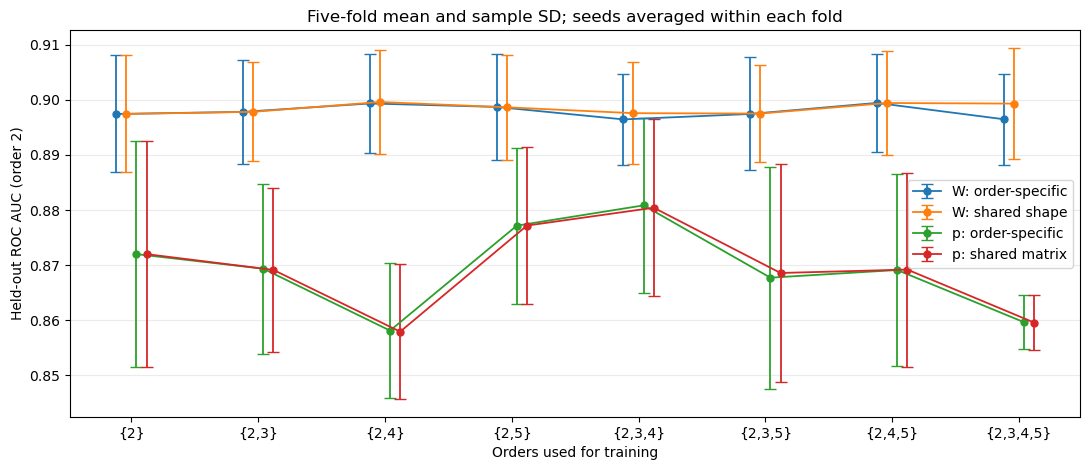

In [6]:
auc_fig = None
if not pairwise_summary.empty:
    auc_fig, auc_ax = plt.subplots(figsize=(11, 4.8))
    auc_x = np.arange(len(ORDER_SETS))
    offsets = np.linspace(-.12, .12, len(MODELS)) if len(MODELS)>1 else [0.]
    for model, offset in zip(MODELS, offsets):
        rows = {tuple(r["train_orders"]):r for r in auc_report["pairwise_auc_summary"]
                if r["model"] == model}
        means = [rows[o]["roc_auc_mean"] if o in rows else np.nan for o in ORDER_SETS]
        stds = [rows[o]["roc_auc_std"] if o in rows else np.nan for o in ORDER_SETS]
        auc_ax.errorbar(auc_x+offset, means, yerr=stds, fmt="o-", capsize=4,
                       linewidth=1.3, markersize=5, label=MODE_LABELS.get(model,model))
    auc_ax.set_xticks(auc_x)
    auc_ax.set_xticklabels(order_labels)
    auc_ax.set_xlabel("Orders used for training")
    auc_ax.set_ylabel("Held-out ROC AUC (order 2)")
    auc_ax.set_title("Five-fold mean and sample SD; seeds averaged within each fold")
    auc_ax.grid(axis="y", alpha=.25)
    auc_ax.legend()
    auc_fig.tight_layout()
    plt.show()


## 6.1 Order-specific and weighted AUC table

Display all order sets and four methods by default, reporting AUC₂–AUC₅ and AUCw as five-fold mean ± sample standard deviation. A dash marks absent orders. Compute weighted AUC within each fold using positive test-edge counts, then calculate its five-fold mean and standard deviation; do not average order-specific standard deviations.

Export HTML, CSV, and a LaTeX table fragment. Duplicate aggregate-AUC curves are disabled by default. This section uses five-fold `W_compare` results, separate from the full-data class evaluation below.

In [7]:
# Display the paper summary table by default; enable aggregate-AUC curves as needed.
SHOW_AGGREGATE_AUC_TABLE = True
SHOW_AGGREGATE_AUC = False
AGGREGATE_ORDER_SETS = None  # Include all eight order sets by default.
AGGREGATE_PLOT_ORDER_SETS = [(2, 3, 4, 5)]
AUC_TABLE_OUTPUT_DIR = Path.cwd() / "outputs" / "highschool_cv_auc_table"
aggregate_auc_fig = None

if SHOW_AGGREGATE_AUC_TABLE or SHOW_AGGREGATE_AUC:
    aggregate_orders = ORDER_SETS if AGGREGATE_ORDER_SETS is None else [tuple(o) for o in AGGREGATE_ORDER_SETS]
    if not set(aggregate_orders).issubset(ORDER_SETS):
        raise ValueError("AGGREGATE_ORDER_SETS包含未评价的阶数组合。")
    order_lookup = {(row["model"], tuple(row["train_orders"]), row["test_order"]): row
                    for row in auc_report["per_order_summary"]}
    aggregate_lookup = {(row["model"], tuple(row["train_orders"])): row
                        for row in auc_report["aggregate_summary"]}
    affinity_names = {"w-differ": "Order-specific W", "w-share": "Shared W",
                      "p-differ": "Order-specific p", "p-share": "Shared p"}
    rows = []
    for orders in aggregate_orders:
        for model in MODELS:
            row = {"D": "{" + ",".join(map(str, orders)) + "}",
                   "Affinity": affinity_names.get(model, model)}
            for d in (2, 3, 4, 5):
                result = order_lookup.get((model, orders, d))
                row[f"AUC{d}"] = "—" if result is None else f"{result['roc_auc_mean']:.3f} ± {result['roc_auc_std']:.3f}"
            result = aggregate_lookup[(model, orders)]
            row["AUCw"] = f"{result['weighted_auc_mean']:.3f} ± {result['weighted_auc_std']:.3f}"
            rows.append(row)
    aggregate_auc_table = pd.DataFrame(rows).set_index(["D", "Affinity"])

    if SHOW_AGGREGATE_AUC_TABLE:
        html = aggregate_auc_table.to_html(border=0, sparsify=True, classes="auc-comparison")
        css = """<style>
        table.auc-comparison {border-collapse:collapse; font-family:'Times New Roman',serif; font-size:14px;}
        table.auc-comparison th, table.auc-comparison td {padding:3px 9px; text-align:center; white-space:nowrap;}
        table.auc-comparison thead {border-top:1.5px solid #333; border-bottom:1px solid #333;}
        table.auc-comparison tbody tr:nth-child(4n+1) > * {border-top:.7px solid #888;}
        table.auc-comparison tbody {border-bottom:1.5px solid #333;}
        table.auc-comparison tbody th {font-weight:normal; vertical-align:top;}
        </style>"""
        table_caption = (
            "Mean ± sample standard deviation across five folds. AUC2–AUC5 are within-order scores; "
            "AUCw is weighted by held-out positive counts within each fold before fold means/SDs are calculated. "
            "Dashes denote orders excluded from the configuration."
        )
        display({"text/html": css + html + '<p style="font-size:12px">' + table_caption + '</p>'}, raw=True)
        AUC_TABLE_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
        aggregate_auc_table.to_csv(AUC_TABLE_OUTPUT_DIR / "auc_comparison.csv", encoding="utf-8-sig")
        (AUC_TABLE_OUTPUT_DIR / "auc_comparison.html").write_text(css + html + '<p>' + table_caption + '</p>', encoding="utf-8")
        (AUC_TABLE_OUTPUT_DIR / "auc_comparison_caption.txt").write_text(table_caption + "\n", encoding="utf-8")

        # Export a booktabs fragment for the paper without recomputing AUC.
        latex = [r"% Requires booktabs and multirow packages.", r"\begin{tabular}{clccccc}", r"\toprule",
                 r"$\mathcal{D}$ & Affinity & $\mathrm{AUC}_2$ & $\mathrm{AUC}_3$ & $\mathrm{AUC}_4$ & $\mathrm{AUC}_5$ & $\mathrm{AUC}_w$ \\", r"\midrule"]
        tex_names = {"w-differ": r"Order-specific $W$", "w-share": r"Shared $W$",
                     "p-differ": r"Order-specific $p$", "p-share": r"Shared $p$"}
        for group_index, orders in enumerate(aggregate_orders):
            for model_index, model in enumerate(MODELS):
                d_cell = (r"\multirow{" + str(len(MODELS)) + r"}{*}{$\{" + ",".join(map(str, orders)) + r"\}$}") if model_index == 0 else ""
                values = []
                for d in (2, 3, 4, 5):
                    result = order_lookup.get((model, orders, d))
                    values.append(r"---" if result is None else f"${result['roc_auc_mean']:.3f} \\pm {result['roc_auc_std']:.3f}$")
                result = aggregate_lookup[(model, orders)]
                values.append(f"${result['weighted_auc_mean']:.3f} \\pm {result['weighted_auc_std']:.3f}$")
                latex.append(" & ".join([d_cell, tex_names.get(model, model)] + values) + r" \\")
            if group_index < len(aggregate_orders) - 1:
                latex.append(r"\midrule")
        latex += [r"\bottomrule", r"\end{tabular}"]
        (AUC_TABLE_OUTPUT_DIR / "auc_comparison.tex").write_text("\n".join(latex) + "\n", encoding="utf-8")

    if SHOW_AGGREGATE_AUC:
        plot_orders = [tuple(values) for values in AGGREGATE_PLOT_ORDER_SETS]
        if not set(plot_orders).issubset(ORDER_SETS):
            raise ValueError("AGGREGATE_PLOT_ORDER_SETS包含未评价的组合。")
        aggregate_auc_fig, ax = plt.subplots(figsize=(8, 4))
        x = np.arange(len(plot_orders))
        offsets = np.linspace(-.12, .12, len(MODELS)) if len(MODELS) > 1 else [0.]
        for model, offset in zip(MODELS, offsets):
            results = [aggregate_lookup[(model, orders)] for orders in plot_orders]
            ax.errorbar(x + offset, [r["weighted_auc_mean"] for r in results],
                        yerr=[r["weighted_auc_std"] for r in results], fmt="o-", capsize=4,
                        label=affinity_names.get(model, model))
        ax.set_xticks(x, ["{" + ",".join(map(str, values)) + "}" for values in plot_orders])
        ax.set_ylabel("Weighted held-out AUC")
        ax.legend()
        aggregate_auc_fig.tight_layout()
        plt.show()


AUC2 
 AUC3 
 AUC4 
 AUC5 
 AUCw 
 
 
 D 
 Affinity 
 
 
 
 
 
 
 
 
 
 {2} 
 Order-specific W 
 0.897 ± 0.011 
 — 
 — 
 — 
 0.897 ± 0.011 
 
 
 Shared W 
 0.897 ± 0.011 
 — 
 — 
 — 
 0.897 ± 0.011 
 
 
 Order-specific p 
 0.872 ± 0.021 
 — 
 — 
 — 
 0.872 ± 0.021 
 
 
 Shared p 
 0.872 ± 0.021 
 — 
 — 
 — 
 0.872 ± 0.021 
 
 
 {2,3} 
 Order-specific W 
 0.898 ± 0.010 
 0.969 ± 0.005 
 — 
 — 
 0.917 ± 0.007 
 
 
 Shared W 
 0.898 ± 0.009 
 0.973 ± 0.005 
 — 
 — 
 0.919 ± 0.007 
 
 
 Order-specific p 
 0.869 ± 0.015 
 0.950 ± 0.008 
 — 
 — 
 0.892 ± 0.012 
 
 
 Shared p 
 0.869 ± 0.015 
 0.955 ± 0.010 
 — 
 — 
 0.893 ± 0.012 
 
 
 {2,4} 
 Order-specific W 
 0.899 ± 0.009 
 — 
 0.962 ± 0.016 
 — 
 0.902 ± 0.008 
 
 
 Shared W 
 0.900 ± 0.009 
 — 
 0.989 ± 0.005 
 — 
 0.903 ± 0.009 
 
 
 Order-specific p 
 0.858 ± 0.012 
 — 
 0.950 ± 0.021 
 — 
 0.862 ± 0.012 
 
 
 Shared p 
 0.858 ± 0.012 
 — 
 0.976 ± 0.009 
 — 
 0.862 ± 0.012 
 
 
 {2,5} 
 Order-specific W 
 0.899 ± 0.010 
 — 
 — 
 0.800 ± 0.447 
 0.899 ± 0.009 
 
 
 Shared W 
 0.899 ± 0.010 
 — 
 — 
 1.000 ± 0.000 
 0.899 ± 0.010 
 
 
 Order-specific p 
 0.877 ± 0.014 
 — 
 — 
 0.850 ± 0.224 
 0.877 ± 0.014 
 
 
 Shared p 
 0.877 ± 0.014 
 — 
 — 
 1.000 ± 0.000 
 0.877 ± 0.014 
 
 
 {2,3,4} 
 Order-specific W 
 0.896 ± 0.008 
 0.969 ± 0.005 
 0.969 ± 0.016 
 — 
 0.918 ± 0.006 
 
 
 Shared W 
 0.898 ± 0.009 
 0.973 ± 0.005 
 0.984 ± 0.004 
 — 
 0.920 ± 0.007 
 
 
 Order-specific p 
 0.881 ± 0.016 
 0.957 ± 0.011 
 0.961 ± 0.022 
 — 
 0.903 ± 0.015 
 
 
 Shared p 
 0.880 ± 0.016 
 0.961 ± 0.011 
 0.980 ± 0.011 
 — 
 0.905 ± 0.014 
 
 
 {2,3,5} 
 Order-specific W 
 0.897 ± 0.010 
 0.968 ± 0.005 
 — 
 0.750 ± 0.433 
 0.917 ± 0.008 
 
 
 Shared W 
 0.898 ± 0.009 
 0.973 ± 0.005 
 — 
 1.000 ± 0.000 
 0.918 ± 0.007 
 
 
 Order-specific p 
 0.868 ± 0.020 
 0.950 ± 0.005 
 — 
 0.700 ± 0.447 
 0.890 ± 0.015 
 
 
 Shared p 
 0.869 ± 0.020 
 0.953 ± 0.003 
 — 
 0.950 ± 0.112 
 0.892 ± 0.015 
 
 
 {2,4,5} 
 Order-specific W 
 0.899 ± 0.009 
 — 
 0.962 ± 0.016 
 0.800 ± 0.447 
 0.902 ± 0.008 
 
 
 Shared W 
 0.899 ± 0.009 
 — 
 0.989 ± 0.005 
 1.000 ± 0.000 
 0.903 ± 0.009 
 
 
 Order-specific p 
 0.869 ± 0.017 
 — 
 0.947 ± 0.028 
 0.950 ± 0.112 
 0.872 ± 0.018 
 
 
 Shared p 
 0.869 ± 0.018 
 — 
 0.965 ± 0.016 
 1.000 ± 0.000 
 0.873 ± 0.017 
 
 
 {2,3,4,5} 
 Order-specific W 
 0.897 ± 0.008 
 0.969 ± 0.005 
 0.969 ± 0.016 
 0.800 ± 0.447 
 0.918 ± 0.006 
 
 
 Shared W 
 0.899 ± 0.010 
 0.973 ± 0.006 
 0.984 ± 0.007 
 1.000 ± 0.000 
 0.922 ± 0.008 
 
 
 Order-specific p 
 0.860 ± 0.005 
 0.935 ± 0.022 
 0.938 ± 0.025 
 0.800 ± 0.447 
 0.882 ± 0.005 
 
 
 Shared p 
 0.860 ± 0.005 
 0.936 ± 0.024 
 0.965 ± 0.023 
 1.000 ± 0.000 
 0.883 ± 0.005 
 
 
 Mean ± sample standard deviation across five folds. AUC2–AUC5 are within-order scores; AUCw is weighted by held-out positive counts within each fold before fold means/SDs are calculated. Dashes denote orders excluded from the configuration.

## 6.2 Four-mode AUC heatmap and paired differences

In [8]:
SHOW_AUC_HEATMAP = False
auc_heatmap_fig = None
if SHOW_AUC_HEATMAP:
    panels = [("weighted_auc",aggregate_summary,"Weighted AUC (positive-count weights)")]
    if not pairwise_summary.empty:
        panels.insert(0,("roc_auc",pairwise_summary,"Order-2 held-out AUC"))
    auc_heatmap_fig, axes = plt.subplots(len(panels),1,
        figsize=(max(8,1.55*len(ORDER_SETS)),max(3,1.1*len(MODELS))*len(panels)),squeeze=False)
    for ax,(metric,frame,title) in zip(axes.ravel(),panels):
        frame = frame.copy()
        frame["D"] = frame["train_orders"].map(order_label)
        means = frame.pivot(index="model",columns="D",values=metric+"_mean").reindex(index=MODELS,columns=order_labels)
        stds = frame.pivot(index="model",columns="D",values=metric+"_std").reindex(index=MODELS,columns=order_labels)
        im=ax.imshow(np.ma.masked_invalid(means.to_numpy(float)),vmin=0,vmax=1,cmap="viridis",aspect="auto")
        for i in range(len(MODELS)):
            for j in range(len(ORDER_SETS)):
                m,s=means.iloc[i,j],stds.iloc[i,j]
                label="—" if pd.isna(m) else f"{m:.3f}\n±{s:.3f}"
                ax.text(j,i,label,ha="center",va="center",fontsize=9,color="white" if pd.isna(m) or m<.55 else "black")
        ax.set_xticks(np.arange(len(order_labels)))
        ax.set_xticklabels(order_labels)
        ax.set_yticks(np.arange(len(MODELS)))
        ax.set_yticklabels(MODELS)
        ax.set_title(title+"; five-fold mean ± SD")
        auc_heatmap_fig.colorbar(im,ax=ax,label="ROC AUC",pad=.02)
    auc_heatmap_fig.tight_layout()
    plt.show()

# Each row compares paired results for the same D; unavailable modes are not filled with zeros.
if SHOW_AUC_TABLES:
    display(paired_auc_comparison)


## 6.3 Save AUC results

Save CSV, JSON, PNG, and PDF in a new directory beside the current results. Compare aggregate AUC only for identical evaluation-order sets. Fifth-order test positives are scarce. Five-fold standard deviations describe variation across folds, not confidence intervals.

In [9]:
if SAVE_AUC_OUTPUTS:
    if AUC_OUTPUT_DIR is None:
        parent = SUMMARY_PATHS[0].parent.parent if SUMMARY_PATHS else CV_ROOT
        timestamp=datetime.now(timezone(timedelta(hours=8))).strftime("%Y%m%d_%H%M%S_%f")
        auc_output_dir=parent/("auc_"+timestamp)
    else:
        auc_output_dir=Path(AUC_OUTPUT_DIR)
    auc_output_dir.mkdir(parents=True,exist_ok=False)
    frames={"auc_per_seed_fold":auc_per_seed_fold,
            "aggregate_per_seed_fold":aggregate_per_seed_fold,
            "auc_per_fold":auc_per_fold,"auc_per_order_summary":auc_summary,
            "pairwise_auc_summary":pairwise_summary,"aggregate_auc_summary":aggregate_summary,
            "paired_auc_comparison":paired_auc_comparison}
    for name,frame in frames.items():
        frame.to_csv(auc_output_dir/(name+".csv"),index=False,encoding="utf-8-sig")
    with (auc_output_dir/"auc_results.json").open("w",encoding="utf-8") as stream:
        json.dump(auc_report,stream,ensure_ascii=False,indent=2,allow_nan=False)
    for name,figure in [("pairwise_auc",auc_fig),("aggregate_auc",aggregate_auc_fig),("auc_heatmap",auc_heatmap_fig)]:
        if figure is not None:
            figure.savefig(auc_output_dir/(name+".png"),dpi=200,bbox_inches="tight")
            figure.savefig(auc_output_dir/(name+".pdf"),bbox_inches="tight")
    print("AUC结果已保存：",auc_output_dir)
else:
    print("结果保留在上述表格与变量中；SAVE_AUC_OUTPUTS=True可导出CSV/JSON和图。")


AUC结果已保存： D:\codex_data\2026-10-19\wo\outputs\D-HySBM-GitHub\outputs\realdata_auc


## 7. Full-data fits: community recovery and structure

Read saved results for four methods from `W_compare_all` without retraining. The current results contain eight order sets and one outer seed. Class labels are used only for subsequent evaluation and plot alignment.

This section can run independently from its configuration below. Default displays include the NMI/ARI overview, p and training W, and class–community soft posteriors. Complete metrics and differences are saved as CSV.

In [10]:
from pathlib import Path
import base64

FULL_RUN_ROOT = PLOT_DATA_DIR / "high_school_cv5/W_compare_all"
FULL_META_CSV = PLOT_DATA_DIR / "high_school_meta.csv"
FULL_DATA_FILE = PLOT_DATA_DIR / "high_school.npz"

# Create a timestamped subdirectory on each run to retain previous analyses.
FULL_OUTPUT_ROOT = Path.cwd() / "outputs" / "highschool_full_fit_analysis"
# Save all eight groups; select one to display in the notebook below.
FULL_SHOW_ORDER_SET = (2, 3, 4, 5)
FULL_SHOW_SEED = 234
# panel scales each matrix by its maximum; shared uses one raw-value color scale for the entire figure.
FULL_AFFINITY_COLOR_SCALE = "panel"


def full_show_saved_png(path):
    path = Path(path)
    if not path.is_file():
        raise FileNotFoundError(f"未找到图：{path}；请检查 FULL_SHOW_ORDER_SET / FULL_SHOW_SEED。")
    # Raw MIME display uses the notebook's built-in display without an extra image dependency.
    display({"image/png": base64.b64encode(path.read_bytes()).decode("ascii")}, raw=True)

# Keep the default display concise; enable additional diagnostics as needed.
FULL_MATRIX_KINDS = ("p", "W_model")  # Add "W_shape" to inspect normalized shape.
FULL_EXTRA_DIAGNOSTICS = False  # Difference plots, metric heatmaps, and MAP confusion matrices.
FULL_SHOW_SUMMARY_TABLE = True


### 7.1 Loading, alignment, and metric functions

The collapsed cell contains the implementation: verify p, n, posteriors, and order metadata against local raw files; align metadata by explicit `nodeID`; and use exact rectangular Hungarian matching for nine classes and ten communities. All layers share the same permutation rather than being aligned separately. NMI/ARI/AMI require no label alignment.

In [11]:
"""Full-data high-school affinity and partition analysis; no fitting, no SciPy/sklearn.

The same source is embedded in realdata_plot.ipynb so that notebook is self-contained.
Only load trusted NPZ files: these saved experiment summaries contain pickled objects.
"""
from pathlib import Path
from datetime import datetime
from collections import Counter
import hashlib
import json
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.cm import ScalarMappable


FULL_MODES = ['w-differ', 'w-share', 'p-differ', 'p-share']
FULL_METRICS = ['nmi', 'ari', 'ami', 'matched_accuracy', 'overlap', 'occupied_communities']
FULL_METRIC_LABELS = ['NMI (arithmetic)', 'ARI', 'AMI (arithmetic)',
                      'Matched accuracy', 'Overlap (majority baseline)', 'Occupied communities']
FULL_COLORS = ['#2463a6', '#df7b18', '#27865d', '#ae588d']


def full_maximum_assignment(weights):
    """Exact rectangular Hungarian assignment, maximizing total weight, O(K^3)."""
    weights = np.asarray(weights, dtype=float)
    if weights.ndim != 2 or not np.isfinite(weights).all():
        raise ValueError('Assignment requires a finite 2-D matrix.')
    transposed = weights.shape[0] > weights.shape[1]
    cost = -weights.T if transposed else -weights
    nr, nc = cost.shape
    u, v = np.zeros(nr + 1), np.zeros(nc + 1)
    matched, previous = np.zeros(nc + 1, dtype=int), np.zeros(nc + 1, dtype=int)
    for i in range(1, nr + 1):
        matched[0] = i
        j0 = 0
        minimum, used = np.full(nc + 1, np.inf), np.zeros(nc + 1, dtype=bool)
        while True:
            used[j0] = True
            i0, delta, j1 = matched[j0], np.inf, 0
            for j in range(1, nc + 1):
                if not used[j]:
                    current = cost[i0 - 1, j - 1] - u[i0] - v[j]
                    if current < minimum[j]:
                        minimum[j], previous[j] = current, j0
                    if minimum[j] < delta:
                        delta, j1 = minimum[j], j
            for j in range(nc + 1):
                if used[j]:
                    u[matched[j]] += delta
                    v[j] -= delta
                else:
                    minimum[j] -= delta
            j0 = j1
            if matched[j0] == 0:
                break
        while j0:
            j1 = previous[j0]
            matched[j0] = matched[j1]
            j0 = j1
    cols = np.flatnonzero(matched[1:] > 0)
    rows = matched[cols + 1] - 1
    return (cols, rows) if transposed else (rows, cols)


def full_contingency(truth, prediction):
    truth, prediction = np.asarray(truth), np.asarray(prediction)
    if truth.ndim != 1 or prediction.shape != truth.shape or truth.size == 0:
        raise ValueError('Labels must be nonempty 1-D arrays with equal lengths.')
    labels_t, ti = np.unique(truth, return_inverse=True)
    labels_p, pi = np.unique(prediction, return_inverse=True)
    table = np.zeros((len(labels_t), len(labels_p)), dtype=np.int64)
    np.add.at(table, (ti, pi), 1)
    return table


def full_partition_metrics(truth, prediction):
    """Permutation-invariant metrics. NMI/AMI use arithmetic mean entropy (nats).

    Overlap follows the project's majority-class baseline, not the uniform 1/K
    baseline. It is undefined for a single true class and can be negative.
    AMI uses the exact hypergeometric null expectation with fixed cluster sizes.
    """
    table = full_contingency(truth, prediction)
    total = int(table.sum())
    a, b = table.sum(axis=1), table.sum(axis=0)
    rows, cols = np.nonzero(table)
    counts = table[rows, cols].astype(float)
    mi = max(0., float(np.sum((counts / total) * np.log(total * counts / (a[rows] * b[cols])))))
    ha = -float(np.sum((a / total) * np.log(a / total)))
    hb = -float(np.sum((b / total) * np.log(b / total)))
    hmean = (ha + hb) / 2
    identical = bool(np.all(np.count_nonzero(table, axis=0) == 1) and
                     np.all(np.count_nonzero(table, axis=1) == 1))
    nmi = 1. if identical else (mi / hmean if hmean > 0 else 0.)
    choose2 = lambda x: int(x) * (int(x) - 1) // 2
    pairs = choose2(total)
    same = sum(choose2(x) for x in table.ravel())
    aa, bb = sum(choose2(x) for x in a), sum(choose2(x) for x in b)
    denominator = pairs * (aa + bb) - 2 * aa * bb
    ari = 2 * (pairs * same - aa * bb) / denominator if denominator else 1.
    if identical:
        ami = 1.
    elif len(a) == 1 or len(b) == 1:
        ami = 0.
    else:
        expectation_terms = []
        for ai in map(int, a):
            for bj in map(int, b):
                normalizer = math.comb(total, bj)
                for nij in range(max(1, ai + bj - total), min(ai, bj) + 1):
                    probability = (math.comb(ai, nij) * math.comb(total - ai, bj - nij)) / normalizer
                    expectation_terms.append((nij / total) * math.log(total * nij / (ai * bj)) * probability)
        expected_mi = math.fsum(expectation_terms)
        ami = (mi - expected_mi) / max(hmean - expected_mi, np.finfo(float).eps)
    rr, cc = full_maximum_assignment(table)
    accuracy = float(table[rr, cc].sum() / total)
    baseline = float(a.max() / total)
    overlap = (accuracy - baseline) / (1 - baseline + 1e-12) if baseline < 1 else np.nan
    return {'nmi': float(nmi), 'ari': float(ari), 'ami': float(ami),
            'matched_accuracy': accuracy, 'overlap': float(overlap),
            'majority_baseline': baseline, 'occupied_communities': int(len(b)),
            'mutual_information_nats': mi, 'true_entropy_nats': ha,
            'pred_entropy_nats': hb, 'variation_information_nats': max(0., ha + hb - 2 * mi)}


def full_affinity_parts(p, n, node_count, orders, c0=None, beta=None):
    """Separate stored p, normalized shape W, and reconstructible trained W.

    W_shape = p / (n.T @ p @ n) for all modes.
    For paper-w only, W_model = p / (c0 * beta[d] / N), retaining clipping effects.
    """
    p, n = np.asarray(p, dtype=float), np.asarray(n, dtype=float)
    if (p.shape != (len(orders), len(n), len(n)) or not np.isfinite(p).all()
            or not np.isfinite(n).all() or (n < 0).any() or (p < 0).any()
            or not np.isclose(n.sum(), 1.) or node_count <= 0):
        raise ValueError('Invalid affinity dimensions, values, or community proportions.')
    actual = np.einsum('i,dij,j->d', n, p, n)
    if (actual <= 0).any():
        raise ValueError('Cannot normalize an affinity layer with zero weighted mean.')
    shape = p / actual[:, None, None]
    target, model, ratio = None, None, None
    if c0 is not None and beta is not None:
        beta = {int(key): float(value) for key, value in beta.items()}
        target = np.array([float(c0) * beta[int(d)] / node_count for d in orders])
        if not np.isfinite(target).all() or (target <= 0).any():
            raise ValueError('Invalid reconstructed layer scale.')
        model = p / target[:, None, None]
        ratio = actual / target
    return {'p': p, 'W_shape': shape, 'W_model': model, 'actual_scale': actual,
            'target_scale': target, 'actual_to_target': ratio}


def full_file_hash(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()


def full_load_results(run_root, meta_csv, data_file):
    """Load local raw files; verify their p/n/q and layer order against summary.

    nodeID in the metadata denotes the original processed hypergraph node index.
    Requiring a complete 0..N-1 index prevents accidental row-order matching.
    """
    run_root, meta_csv, data_file = map(lambda x: Path(x).expanduser().resolve(),
                                      (run_root, meta_csv, data_file))
    summary_file = run_root / 'summary' / 'summary.npz'
    with np.load(summary_file, allow_pickle=True) as saved:
        case_results = list(saved['case_results'])
    if not case_results:
        raise ValueError('No full-data cases found.')
    meta = pd.read_csv(meta_csv)
    needed = {'nodeID', 'class', 'classID'}
    if not needed.issubset(meta.columns) or meta[list(needed)].isna().any().any():
        raise ValueError(f'Metadata requires nonmissing {needed}.')
    ids = meta['nodeID'].to_numpy()
    node_count = np.asarray(case_results[0]['log_marginals']).shape[0]
    if (not np.issubdtype(ids.dtype, np.integer) or len(meta) != node_count
            or not np.array_equal(np.sort(ids), np.arange(node_count))):
        raise ValueError('Metadata nodeID must be a unique complete index 0..N-1.')
    meta = meta.set_index('nodeID', drop=False).loc[np.arange(node_count)].copy()
    if meta.groupby('classID')['class'].nunique().max() != 1 or meta.groupby('class')['classID'].nunique().max() != 1:
        raise ValueError('classID and class name must have a one-to-one mapping.')
    class_table = meta[['classID', 'class']].drop_duplicates().sort_values('classID')
    class_ids = class_table['classID'].to_numpy()
    class_names = class_table['class'].astype(str).tolist()
    class_index = {value: i for i, value in enumerate(class_ids)}
    true_labels = np.array([class_index[value] for value in meta['classID']])
    with np.load(data_file, allow_pickle=True) as data:
        edges = [tuple(map(int, edge)) for edge in data['hyperedges']]
        weights = np.asarray(data['A'], dtype=float) if 'A' in data else np.ones(len(edges))
    if len(weights) != len(edges) or min(min(edge) for edge in edges) < 0 or max(max(edge) for edge in edges) >= node_count:
        raise ValueError('Processed hypergraph is inconsistent with inferred node indices.')
    order_counts = Counter(map(len, edges))
    order_weights = {d: float(sum(w for edge, w in zip(edges, weights) if len(edge) == d)) for d in order_counts}
    protocol_file, status_file = run_root / 'protocol.json', run_root / 'status.json'
    protocol = json.loads(protocol_file.read_text(encoding='utf-8')) if protocol_file.exists() else {}
    status = json.loads(status_file.read_text(encoding='utf-8')) if status_file.exists() else {}
    cases, keys, raw_paths = [], set(), []
    for saved_case in case_results:
        mode, dataset = str(saved_case['mode']), str(saved_case['dataset'])
        orders = tuple(map(int, saved_case['selected_hye_sizes']))
        seed, case_index = int(saved_case['seed']), int(saved_case['idx_sizes'])
        key = (mode, orders, seed)
        if mode not in FULL_MODES or dataset != 'high_school' or key in keys:
            raise ValueError(f'Unexpected or duplicate full-data case: {key}, dataset={dataset}.')
        keys.add(key)
        raw_file = (run_root / mode / dataset /
                    f'case_{case_index:03d}_sizes_{"_".join(map(str, orders))}' /
                    f'seed_{seed}' / 'mp_results' / 'inferred_params.npz')
        with np.load(raw_file, allow_pickle=True) as raw:
            for field in ['p', 'n', 'log_marginals']:
                if not np.array_equal(np.asarray(raw[field]), np.asarray(saved_case[field])):
                    raise ValueError(f'Summary/raw disagree: {field}, {raw_file}')
            raw_orders = tuple(map(int, raw['selected_hye_sizes']))
            if raw_orders != orders:
                raise ValueError(f'Affinity layer order mismatch: {raw_file}')
            c0 = raw['c0'].item() if 'c0' in raw else None
            beta = raw['effective_beta_d'].item() if 'effective_beta_d' in raw else None
            p, n, logq = (np.asarray(raw[field], dtype=float) for field in ['p', 'n', 'log_marginals'])
        if logq.shape != (node_count, len(n)) or not np.isfinite(logq).all():
            raise ValueError(f'Invalid posterior dimensions or values: {raw_file}')
        q = np.exp(logq - logq.max(axis=1, keepdims=True))
        q /= q.sum(axis=1, keepdims=True)
        if not np.allclose(p, p.swapaxes(1, 2), atol=1e-10, rtol=1e-10):
            raise ValueError(f'Asymmetric affinity: {raw_file}')
        parts = full_affinity_parts(p, n, node_count, orders, c0, beta)
        if mode.startswith('w-') and parts['W_model'] is None:
            raise ValueError(f'Cannot reconstruct trained W for {raw_file}')
        prediction = q.argmax(axis=1)
        metrics = full_partition_metrics(true_labels, prediction)
        confusion = np.zeros((len(class_names), len(n)), dtype=int)
        np.add.at(confusion, (true_labels, prediction), 1)
        rr, cc = full_maximum_assignment(confusion)
        matching = dict(zip(map(int, rr), map(int, cc)))
        permutation = [matching[i] for i in range(len(class_names)) if i in matching]
        extras = sorted(set(range(len(n))) - set(permutation), key=lambda i: (-n[i], i))
        permutation += extras
        hard_n = np.bincount(prediction, minlength=len(n)) / node_count
        axis_labels = [f'{class_names[i]}:g{matching[i]}' for i in range(len(class_names)) if i in matching]
        axis_labels += [f'extra:g{i}' for i in extras]
        axis_labels = [label + (' [0]' if hard_n[community] == 0 else '')
                       for label, community in zip(axis_labels, permutation)]
        cases.append({'mode': mode, 'orders': orders, 'order_set': '+'.join(map(str, orders)),
                      'seed': seed, 'K': len(n), 'N': node_count, 'n': n, 'q': q,
                      'prediction': prediction, 'true_labels': true_labels,
                      'confusion': confusion, 'class_names': class_names,
                      'permutation': permutation, 'axis_labels': axis_labels,
                      'parts': parts, 'raw_path': str(raw_file), 'c0': c0, 'beta': beta,
                      'metrics': {**metrics,
                          'mean_posterior_confidence': float(q.max(axis=1).mean()),
                          'mean_posterior_entropy_nats': float(-np.sum(q * np.log(np.maximum(q, 1e-300)), axis=1).mean()),
                          'n_vs_posterior_l1': float(np.abs(n - q.mean(axis=0)).sum()),
                          'n_vs_hard_l1': float(np.abs(n - hard_n).sum()),
                          'best_free_energy': float(saved_case['best_free_energy']),
                          'em_total_time_seconds': float(saved_case.get('em_total_time', np.nan))}})
        raw_paths.append({'path': str(raw_file), 'sha256': full_file_hash(raw_file)})
    config = protocol.get('configuration', {})
    sets = sorted({tuple(map(int, values)) for values in config.get(
        'order_sets', [case['orders'] for case in cases])}, key=lambda x: (len(x), x))
    seeds = sorted(set(map(int, config.get('seeds', [case['seed'] for case in cases]))))
    modes = list(config.get('modes', FULL_MODES))
    expected = {(mode, orders, seed) for mode in modes for orders in sets for seed in seeds}
    missing = expected - keys
    if missing or keys - expected:
        raise ValueError(f'Full-data comparison differs from protocol: missing={sorted(missing)}, extra={sorted(keys - expected)}')
    input_hashes = [value for key, value in protocol.get('inputs', {}).items()
                    if Path(key).name == data_file.name]
    data_hash = full_file_hash(data_file)
    if input_hashes and any(value != data_hash for value in input_hashes):
        raise ValueError('Local processed hypergraph SHA256 differs from training protocol.')
    audit = {'run_root': str(run_root), 'summary_path': str(summary_file),
             'summary_sha256': full_file_hash(summary_file), 'data_path': str(data_file),
             'data_sha256': data_hash, 'metadata_path': str(meta_csv),
             'metadata_sha256': full_file_hash(meta_csv), 'raw_files': raw_paths,
             'cases': len(cases), 'node_count': node_count, 'true_classes': len(class_names),
             'model_K': sorted(set(case['K'] for case in cases)), 'seeds': seeds,
             'order_sets': [list(x) for x in sets], 'unique_edges_by_order': dict(order_counts),
             'edge_weight_sum_by_order': order_weights, 'protocol': protocol, 'status': status,
             'evaluation': 'Full-data post-hoc class agreement; not cross-validation or test AUC.',
             'matrix_alignment': 'One rectangular Hungarian permutation per fitted case, shared by all its layers.',
             'W_shape': 'p_d / (n.T @ p_d @ n); derived normalized shape for every mode.',
             'W_model': 'paper-w only: p_d / (c0 * effective_beta_d[d] / N); preserves clipping.',
             'overlap': '(matched_accuracy - largest_true_class_fraction) / (1 - largest_true_class_fraction + 1e-12)',
             'uncertainty': 'No error bars for a single outer seed. Internal restarts are not replicate samples.'}
    return cases, meta, audit


def full_summary_tables(cases):
    records, affinities, entries, alignment = [], [], [], []
    for case in cases:
        identity = {name: case[name] for name in ['mode', 'order_set', 'seed', 'N', 'K']}
        records.append({**identity, **case['metrics'], 'raw_path': case['raw_path']})
        parts, permutation = case['parts'], np.asarray(case['permutation'])
        for position, community in enumerate(permutation):
            alignment.append({**identity, 'plot_position': position, 'original_community': int(community),
                              'plot_label': case['axis_labels'][position], 'n': float(case['n'][community]),
                              'hard_count': int(np.sum(case['prediction'] == community)),
                              'posterior_mean': float(case['q'][:, community].mean())})
        for layer, order in enumerate(case['orders']):
            target = parts['target_scale'][layer] if parts['target_scale'] is not None else np.nan
            ratio = parts['actual_to_target'][layer] if parts['actual_to_target'] is not None else np.nan
            affinities.append({**identity, 'order': order, 'actual_scale': parts['actual_scale'][layer],
                               'target_scale': target, 'actual_to_target': ratio,
                               'W_model_available': parts['W_model'] is not None,
                               'p_min': float(parts['p'][layer].min()), 'p_max': float(parts['p'][layer].max()),
                               'W_shape_max': float(parts['W_shape'][layer].max())})
            for i, a in enumerate(permutation):
                for j, b in enumerate(permutation):
                    entries.append({**identity, 'order': order, 'row': i, 'column': j,
                                    'row_label': case['axis_labels'][i], 'column_label': case['axis_labels'][j],
                                    'original_row': int(a), 'original_column': int(b),
                                    'p': parts['p'][layer, a, b], 'W_shape': parts['W_shape'][layer, a, b],
                                    'W_model': parts['W_model'][layer, a, b] if parts['W_model'] is not None else np.nan})
    metrics = pd.DataFrame(records)
    metric_names = ['nmi', 'ari', 'ami', 'matched_accuracy', 'overlap', 'occupied_communities']
    base = metrics.loc[metrics['order_set'] == '2', ['mode', 'seed'] + metric_names]
    if len(base) != len(metrics[['mode', 'seed']].drop_duplicates()):
        raise ValueError('A two-node-order baseline is required for delta calculations.')
    deltas = metrics.merge(base, on=['mode', 'seed'], how='left', suffixes=('', '_baseline2'), validate='many_to_one')
    for name in metric_names:
        deltas[f'delta_{name}'] = deltas[name] - deltas[f'{name}_baseline2']
    wd = metrics.loc[metrics['mode'] == 'w-differ', ['order_set', 'seed'] + metric_names]
    mode_deltas = metrics.merge(wd, on=['order_set', 'seed'], how='left', suffixes=('', '_w_differ'), validate='many_to_one')
    for name in metric_names:
        mode_deltas[f'delta_{name}'] = mode_deltas[name] - mode_deltas[f'{name}_w_differ']
    return {'metrics': metrics, 'delta_vs_order2': deltas, 'delta_vs_w_differ': mode_deltas,
            'affinity_scales': pd.DataFrame(affinities), 'affinity_entries_aligned': pd.DataFrame(entries),
            'community_alignment': pd.DataFrame(alignment)}


def full_metric_figures(tables, order_sets, include_diagnostics=False):
    """One point per mode/order set; means across outer seeds if multiple, no fake CI."""
    labels = ['+'.join(map(str, orders)) for orders in order_sets]
    figures = {}
    if not include_diagnostics:
        frame = tables['metrics']
        method_labels = [r'Order-specific $W$', r'Shared $W$', r'Order-specific $p$', r'Shared $p$']
        fig, axes = plt.subplots(1, 2, figsize=(180 / 25.4, 76 / 25.4), facecolor='white')
        fig.subplots_adjust(left=.075, right=.985, bottom=.29, top=.90, wspace=.25)
        for panel, (ax, metric, title) in enumerate(zip(axes, ['nmi', 'ari'], ['NMI', 'ARI'])):
            for mode, color, label in zip(FULL_MODES, FULL_COLORS, method_labels):
                grouped = frame.loc[frame['mode'] == mode].groupby('order_set')[metric].mean().reindex(labels)
                ax.plot(range(len(labels)), grouped, 'o-', color=color, label=label, linewidth=1.1, markersize=3)
            ax.set_xticks(range(len(labels)), labels, rotation=40, ha='right', fontsize=7)
            ax.tick_params(axis='y', labelsize=7, length=3)
            ax.set_title(f'({chr(ord("a") + panel)}) {title}', fontsize=9, loc='left')
            ax.set_ylim(float(frame[metric].min()) - .035, 1.005)
            ax.grid(axis='y', color='#dddddd', linewidth=.5)
            ax.spines[['top', 'right']].set_visible(False)
        handles, legend_labels = axes[0].get_legend_handles_labels()
        fig.legend(handles, legend_labels, loc='lower center', ncol=4, frameon=False,
                   fontsize=7, bbox_to_anchor=(.52, .005), handlelength=1.5, columnspacing=1.3)
        return {'metrics': fig}
    for table_name, prefix, title in [('metrics', '', 'Full-data class agreement'),
                                      ('delta_vs_order2', 'delta_', 'Change from order 2 (same mode / seed)'),
                                      ('delta_vs_w_differ', 'delta_', 'Change from w-differ (same orders / seed)')]:
        frame = tables[table_name]
        fig, axes = plt.subplots(2, 3, figsize=(15, 8), constrained_layout=True)
        for ax, metric, text in zip(axes.flat, FULL_METRICS, FULL_METRIC_LABELS):
            for mode, color in zip(FULL_MODES, FULL_COLORS):
                subset = frame[frame['mode'] == mode]
                grouped = subset.groupby('order_set')[prefix + metric].mean().reindex(labels)
                ax.plot(range(len(labels)), grouped, 'o-', color=color, label=mode, linewidth=1.6, markersize=4)
            ax.set_xticks(range(len(labels)), labels, rotation=40, ha='right')
            ax.set_title(('Delta ' if prefix else '') + text, fontsize=11)
            ax.grid(alpha=.2)
            if prefix:
                ax.axhline(0, color='#555555', linewidth=.8)
            elif metric in ['nmi', 'matched_accuracy']:
                ax.set_ylim(0, 1.02)
        axes[0, 0].legend(fontsize=9)
        fig.suptitle(title + ('; outer-seed mean' if frame['seed'].nunique() > 1
                             else f"; seed {int(frame['seed'].iloc[0])}"), fontsize=14)
        figures[table_name] = fig
    fig, axes = plt.subplots(1, 3, figsize=(17, 4), constrained_layout=True)
    for ax, metric, title in zip(axes, ['nmi', 'ari', 'matched_accuracy'], ['NMI', 'ARI', 'Matched accuracy']):
        grid = tables['metrics'].pivot_table(index='mode', columns='order_set', values=metric).reindex(index=FULL_MODES, columns=labels)
        image = ax.imshow(grid, vmin=min(0., float(np.nanmin(grid))), vmax=1, cmap='viridis', aspect='auto')
        ax.set_xticks(range(len(labels)), labels, rotation=45, ha='right')
        ax.set_yticks(range(len(FULL_MODES)), FULL_MODES)
        ax.set_title(title)
        for i in range(len(FULL_MODES)):
            for j in range(len(labels)):
                value = grid.iloc[i, j]
                ax.text(j, i, f'{value:.3f}', ha='center', va='center', fontsize=8,
                        color='white' if value < .55 else 'black')
        fig.colorbar(image, ax=ax, shrink=.8)
    figures['metric_heatmaps'] = fig
    return figures


def _full_affinity_annotation(value):
    """Keep exactly the existing numerical annotation convention."""
    value = float(value)
    if value == 0.:
        return '0'
    if value < .005:
        return '<0.01'
    if value < 10.:
        return f'{value:.2f}'
    if value < 1000.:
        return f'{value:.1f}'
    return f'{value:.1e}'


def _full_affinity_paper_ticks(case):
    labels = []
    for original in case['axis_labels']:
        label = original.split(':g', 1)[0]
        label = 'Extra' if label.lower() == 'extra' else label
        if '[0]' in original:
            label += r'$^{\dagger}$'
        labels.append(label)
    return labels


def _full_affinity_paper_cmap():
    colors = plt.get_cmap('Reds')(np.linspace(0, 1, 256))
    colors[0] = [1., 1., 1., 1.]
    return LinearSegmentedColormap.from_list('affinity_appendix_reds', colors)


def _full_affinity_draw_panel(ax, case, kind, layer, cmap, maximum, color_scale,
                              show_x=True, show_y=True):
    permutation = np.asarray(case['permutation'])
    matrix = case['parts'][kind][layer][np.ix_(permutation, permutation)]
    panel_maximum = float(matrix.max())
    norm = Normalize(0., max(panel_maximum if color_scale == 'panel' else maximum, np.finfo(float).tiny))
    ax.imshow(matrix, cmap=cmap, norm=norm, interpolation='nearest')
    for a, b in np.ndindex(matrix.shape):
        value = float(matrix[a, b])
        rgba = cmap(norm(value))
        luminance = .2126 * rgba[0] + .7152 * rgba[1] + .0722 * rgba[2]
        ax.text(b, a, _full_affinity_annotation(value), ha='center', va='center',
                fontsize=6.2,
                color='white' if luminance < .46 else '#492020')
    ticks = _full_affinity_paper_ticks(case)
    x_ticks = [label.replace(r'$^{\dagger}$', '') for label in ticks]
    ax.set_xticks(range(case['K']), x_ticks if show_x else [''] * case['K'], rotation=90,
                  fontsize=6.5)
    ax.set_yticks(range(case['K']), ticks if show_y else [''] * case['K'],
                  fontsize=6.5)
    ax.tick_params(length=0, pad=2)
    for spine in ax.spines.values():
        spine.set_visible(False)
    return panel_maximum


def _full_affinity_fit_text(fig, axes):
    """Fit every existing numeric label into its cell; do not hide any values."""
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    for ax in axes:
        cell_width = ax.get_window_extent(renderer).width / len(ax.get_xticks())
        for text in ax.texts:
            width = text.get_window_extent(renderer).width
            if width > .88 * cell_width:
                text.set_fontsize(text.get_fontsize() * .88 * cell_width / width)


def _full_affinity_attach_caption(fig, selected, kind, color_scale, panel_maxima):
    names = {'w-differ': 'order-specific W', 'w-share': 'shared W',
             'p-differ': 'order-specific p', 'p-share': 'shared p'}
    quantities = {'p': 'Fitted affinity matrices p^(d)',
                  'W_model': 'Structural matrices W^(d) recovered as p^(d)/(c0 beta_d/N), retaining clipping effects',
                  'W_shape': 'Mean-normalized shape matrices p^(d)/(n^T p^(d) n)'}
    orders = ', '.join(map(str, selected[0]['orders']))
    method_text = ', '.join(names[c['mode']] for c in selected) + ' models'
    arrangement = 'Rows correspond to inference models and columns to hyperedge orders.'
    color_text = ('Colors show each entry divided by the maximum in its panel; equal colors across panels do not imply equal raw values.'
                  if color_scale == 'panel' else 'All panels share one linear color scale in the original parameter units.')
    caption = (f'{quantities[kind]} for the {method_text}, using hyperedge orders {{{orders}}}. '
               f'{arrangement} Both matrix axes use the same class-aligned community order, obtained from one '
               'Hungarian matching per fitted model and retained across orders. Every cell retains its original numeric '
               f'annotation. {color_text} A dagger on a row label denotes a community with no MAP-assigned nodes '
               'for the corresponding model; its entries are retained. '
               'Class names label alignment positions and do not imply that empty communities recover those classes. '
               'Original community IDs and fitted values are provided in the alignment and matrix-entry tables.\n')
    fig._affinity_caption = caption
    fig._affinity_metadata = {'kind': kind, 'color_scale': color_scale, 'orders': list(selected[0]['orders']),
                              'methods': [case['mode'] for case in selected], 'panel_maxima': panel_maxima,
                              'raw_sources': [case['raw_path'] for case in selected],
                              'all_cells_annotated': True, 'view': 'method-by-order grid'}


def _full_affinity_colorbar(fig, grid_cell, cmap, maximum, color_scale, kind):
    norm = Normalize(0., 1. if color_scale == 'panel' else maximum)
    colorbar = fig.colorbar(ScalarMappable(norm=norm, cmap=cmap), cax=fig.add_subplot(grid_cell))
    if color_scale == 'panel':
        colorbar.set_ticks([0, .5, 1])
        label = 'Relative intensity'
    else:
        label = {'p': r'$p_{ab}^{(d)}$', 'W_model': r'$W_{ab}^{(d)}$',
                 'W_shape': r'$\widetilde{W}_{ab}^{(d)}$'}[kind]
    colorbar.set_label(label, fontsize=8, labelpad=5)
    colorbar.ax.tick_params(labelsize=7, length=0, pad=3)
    colorbar.outline.set_visible(False)


def full_affinity_figure(selected, kind, color_scale='panel'):
    """Method-by-order overview, without fit diagnostics in panel titles."""
    selected = sorted([case for case in selected if case['parts'][kind] is not None],
                      key=lambda case: FULL_MODES.index(case['mode']))
    if not selected or color_scale not in {'panel', 'shared'}:
        raise ValueError('No affinity layers selected, or invalid color scale.')
    orders = selected[0]['orders']
    nr, nc = len(selected), len(orders)
    width_mm = min(280, 80 * nc + 20)
    height_mm = nr * (width_mm * .78 / nc + 14) + 15
    fig = plt.figure(figsize=(width_mm / 25.4, height_mm / 25.4), facecolor='white')
    grid = fig.add_gridspec(nr, nc + 1, width_ratios=[*([1] * nc), .045],
                            left=.18 if nc == 1 else .12, right=.86 if nc == 1 else .92,
                            bottom=.11, top=.955, wspace=.13, hspace=.10)
    maximum = max(float(case['parts'][kind].max()) for case in selected)
    cmap, axes, maxima = _full_affinity_paper_cmap(), [], []
    names = {'w-differ': r'Order-specific $W$', 'w-share': r'Shared $W$',
             'p-differ': r'Order-specific $p$', 'p-share': r'Shared $p$'}
    for i, case in enumerate(selected):
        for j, order in enumerate(orders):
            ax = fig.add_subplot(grid[i, j])
            axes.append(ax)
            maxima.append(_full_affinity_draw_panel(ax, case, kind, j, cmap, maximum, color_scale,
                                                    show_x=i == nr - 1, show_y=j == 0))
            index = i * nc + j
            letter = chr(ord('a') + index)
            ax.set_title(f'({letter})' + (f' $d={order}$' if i == 0 else ''), fontsize=8,
                          loc='left', pad=5)
            if j == 0:
                ax.set_ylabel(names[case['mode']], fontsize=8, labelpad=10)
    _full_affinity_colorbar(fig, grid[:, -1], cmap, maximum, color_scale, kind)
    fig.supxlabel('Community', fontsize=8, y=.015)
    _full_affinity_fit_text(fig, axes)
    _full_affinity_attach_caption(fig, selected, kind, color_scale, maxima)
    return fig


def full_save_affinity_publication_figure(fig, output_dir, stem):
    """Save physical-size PNG/PDF/SVG plus separate caption and provenance."""
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    paths = []
    with plt.rc_context({'font.family': 'DejaVu Sans', 'pdf.fonttype': 42,
                         'ps.fonttype': 42, 'svg.fonttype': 'none'}):
        for extension in ['png', 'pdf', 'svg']:
            path = output_dir / f'{stem}.{extension}'
            fig.savefig(path, dpi=600, facecolor='white')
            paths.append(str(path))
    (output_dir / f'{stem}_caption.txt').write_text(fig._affinity_caption, encoding='utf-8')
    (output_dir / f'{stem}_provenance.json').write_text(json.dumps(fig._affinity_metadata, ensure_ascii=False, indent=2), encoding='utf-8')
    return paths


def full_confusion_figure(selected):
    selected = sorted(selected, key=lambda case: FULL_MODES.index(case['mode']))
    fig, axes = plt.subplots(2, 2, figsize=(15, 10), constrained_layout=True)
    for ax, case in zip(axes.flat, selected):
        matrix = case['confusion'][:, case['permutation']]
        fractions = matrix / matrix.sum(axis=1, keepdims=True)
        image = ax.imshow(fractions, vmin=0, vmax=1, cmap='Blues', aspect='auto')
        ax.set_yticks(range(len(case['class_names'])), case['class_names'])
        ax.set_xticks(range(case['K']), case['axis_labels'], rotation=55, ha='right', fontsize=8)
        ax.set_title(f"{case['mode']} | NMI {case['metrics']['nmi']:.3f} | acc {case['metrics']['matched_accuracy']:.3f}")
        for i, j in zip(*np.nonzero(matrix)):
            ax.text(j, i, str(matrix[i, j]), ha='center', va='center', fontsize=8,
                    color='white' if fractions[i, j] > .55 else 'black')
    fig.colorbar(image, ax=axes.ravel().tolist(), shrink=.7, label='Fraction within true class; annotations = node counts')
    fig.suptitle(f"Class versus inferred community | orders {selected[0]['order_set']} | seed {selected[0]['seed']}")
    return fig


def full_run_analysis(run_root, meta_csv, data_file, output_root, display_order_sets=((2, 3, 4, 5),),
                      show=True, save_figures=True, affinity_color_scale='panel',
                      affinity_kinds=('p', 'W_model'), include_diagnostic_figures=False):
    """Analyze every saved case. Does not train or select fits using class labels."""
    cases, meta, audit = full_load_results(run_root, meta_csv, data_file)
    tables = full_summary_tables(cases)
    if not affinity_kinds or set(affinity_kinds) - {'p', 'W_shape', 'W_model'}:
        raise ValueError('Select p, W_shape, and/or W_model for affinity plots.')
    output_dir = Path(output_root).expanduser().resolve() / datetime.now().strftime('%Y%m%d_%H%M%S_%f')
    output_dir.mkdir(parents=True, exist_ok=False)
    for name, frame in tables.items():
        frame.to_csv(output_dir / f'{name}.csv', index=False, encoding='utf-8-sig')
    audit['column_permutations'] = [{**{k: case[k] for k in ['mode', 'order_set', 'seed']},
                                    'permutation': case['permutation'], 'labels': case['axis_labels']} for case in cases]
    audit['affinity_plot_style'] = {'palette': 'white to red', 'color_scale': affinity_color_scale,
                                    'cell_annotations': 'raw values, positive values below .005 shown as <0.01',
                                    'panel_titles': 'panel letters and hyperedge orders; method names as row labels',
                                    'empty_community_marker': 'dagger on aligned community tick labels'}
    audit['affinity_plot_kinds'] = list(affinity_kinds)
    audit['diagnostic_figures'] = bool(include_diagnostic_figures)
    (output_dir / 'provenance.json').write_text(json.dumps(audit, ensure_ascii=False, indent=2), encoding='utf-8')
    figure_paths, display_images = [], []
    def save_or_show(fig, stem, display_figure):
        if save_figures:
            if hasattr(fig, '_affinity_caption'):
                figure_paths.extend(full_save_affinity_publication_figure(fig, output_dir, stem))
            else:
                for extension in ['png', 'pdf']:
                    path = output_dir / f'{stem}.{extension}'
                    fig.savefig(path, dpi=160, bbox_inches='tight')
                    figure_paths.append(str(path))
            if display_figure:
                display_images.append(str(output_dir / f'{stem}.png'))
        if show and display_figure:
            try:
                from IPython.display import display
                display(fig)
            except ImportError:
                fig.show()
        plt.close(fig)
    sets = [tuple(x) for x in audit['order_sets']]
    for name, fig in full_metric_figures(tables, sets, include_diagnostics=include_diagnostic_figures).items():
        save_or_show(fig, name, True)
    display_sets = set(map(tuple, display_order_sets))
    for seed in audit['seeds']:
        for orders in sets:
            selected = [case for case in cases if case['orders'] == orders and case['seed'] == seed]
            suffix = f'orders_{"-".join(map(str, orders))}_seed_{seed}'
            for kind in affinity_kinds:
                save_or_show(full_affinity_figure(selected, kind, color_scale=affinity_color_scale),
                             f'affinity_{kind}_{suffix}', orders in display_sets)
            if include_diagnostic_figures:
                save_or_show(full_confusion_figure(selected), f'class_confusion_{suffix}', orders in display_sets)
    readme = f'''Full-data high-school analysis

Cases: {len(cases)}; nodes: {audit['node_count']}; true classes: {audit['true_classes']}; model K: {audit['model_K']}; seeds: {audit['seeds']}.
Exported affinity plots: {', '.join(affinity_kinds)}. Additional diagnostic figures: {include_diagnostic_figures}.
metrics.csv: NMI/AMI arithmetic normalization, ARI, Hungarian matched accuracy, project-defined Overlap, occupied communities, posterior diagnostics.
delta_vs_order2.csv: metric change against order 2 within the same mode and outer seed.
delta_vs_w_differ.csv: metric change against w-differ within the same order set and outer seed.
affinity_scales.csv: n.T p n, nominal c0 beta_d/N and actual/nominal ratio (paper-w only).
affinity_entries_aligned.csv: every p/W matrix entry in the plotted class-aligned order.
community_alignment.csv and provenance.json: original labels, permutations, file hashes and provenance.

p: original stored affinity.
W_shape: p/(n.T p n), a derived normalized shape for every method. For direct-p this is post-hoc, not a trained W parameter.
W_model: reconstructed trained W for paper-w only, p/(c0 beta_d/N). Do not renormalize away clipping effects.
Axes: class:gX means gX is assigned to that class by one rectangular Hungarian match per fit; unmatched extra communities are retained.
NMI/ARI/AMI are permutation invariant; true classes are used only for evaluation/plot alignment, never fitting or choosing restarts.
Overlap=(accuracy-largest true-class fraction)/(1-largest true-class fraction+1e-12), as in this project; may be negative.
Matched accuracy is one-to-one and penalizes the extra community when model K exceeds the number of classes.
These are full-data post-hoc agreements, not five-fold test scores. A single outer seed supplies no replicate standard deviation or confidence interval.
Matrix figures use white-to-red colors and raw-value cell annotations; positive values below .005 are labelled <0.01. The default is normalization to each panel maximum, which is printed in its title; the colorbar is relative, not an absolute cross-panel magnitude. Set affinity_color_scale='shared' for a shared absolute linear color scale. Empty communities are retained; [0] marks empty MAP communities, whose parameters are weakly identified.
The saved selected fit is used as-is; internal restarts are not independent evaluation samples. Free energies of different fitted models are diagnostics, not directly comparable evidence.
'''
    (output_dir / 'README.txt').write_text(readme, encoding='utf-8')
    print(f"Full-data fits: {len(cases)} | N={audit['node_count']} | true classes={audit['true_classes']} | K={audit['model_K']} | seeds={audit['seeds']}")
    print(f'Outputs: {output_dir}')
    return {'cases': cases, 'metadata': meta, 'audit': audit, 'tables': tables,
            'output_dir': output_dir, 'figure_paths': figure_paths, 'display_images': display_images}


### 7.2 Load and evaluate results

Compute NMI, ARI, AMI, one-to-one matching accuracy, Overlap, and occupied-community count. NMI/AMI use arithmetic normalization; Overlap retains the project's majority-class baseline. Export all fit-level values and differences from second order and w-differ as CSV.

Display a compact table for the selected order set and save the full table separately. The current data have one outer seed, so no replicate error bars are plotted; internal restarts are not independent replicates.

In [12]:
FULL_REPORT = full_run_analysis(
    FULL_RUN_ROOT, FULL_META_CSV, FULL_DATA_FILE, FULL_OUTPUT_ROOT,
    display_order_sets=(FULL_SHOW_ORDER_SET,), show=False, save_figures=True,
    affinity_color_scale=FULL_AFFINITY_COLOR_SCALE,
    affinity_kinds=FULL_MATRIX_KINDS,
    include_diagnostic_figures=FULL_EXTRA_DIAGNOSTICS,
)
FULL_TABLES = FULL_REPORT["tables"]
FULL_RESULT_DIR = FULL_REPORT["output_dir"]
FULL_METRICS_DF = FULL_TABLES["metrics"]
if FULL_SHOW_SUMMARY_TABLE:
    selected = FULL_METRICS_DF["order_set"] == "+".join(map(str, FULL_SHOW_ORDER_SET))
    display(FULL_METRICS_DF.loc[selected, ["mode", "nmi", "ari", "ami", "matched_accuracy", "overlap"]].round(4))


Full-data fits: 32 | N=327 | true classes=9 | K=[10] | seeds=[234]
Outputs: D:\codex_data\2026-10-19\wo\outputs\D-HySBM-GitHub\outputs\highschool_full_fit_analysis\20261019_133252_788711


,mode,nmi,ari,ami,matched_accuracy,overlap
7,w-differ,0.9388,0.9334,0.9353,0.9541,0.9470
15,w-share,0.9559,0.9498,0.9533,0.9664,0.9611
23,p-differ,0.8455,0.6596,0.8402,0.7003,0.6537
31,p-share,0.8592,0.6675,0.8543,0.7064,0.6608


### 7.3 Community recovery metrics

Show NMI and ARI for every training order set. Other metrics and differences are in CSV; `FULL_EXTRA_DIAGNOSTICS=True` additionally exports diagnostic figures.

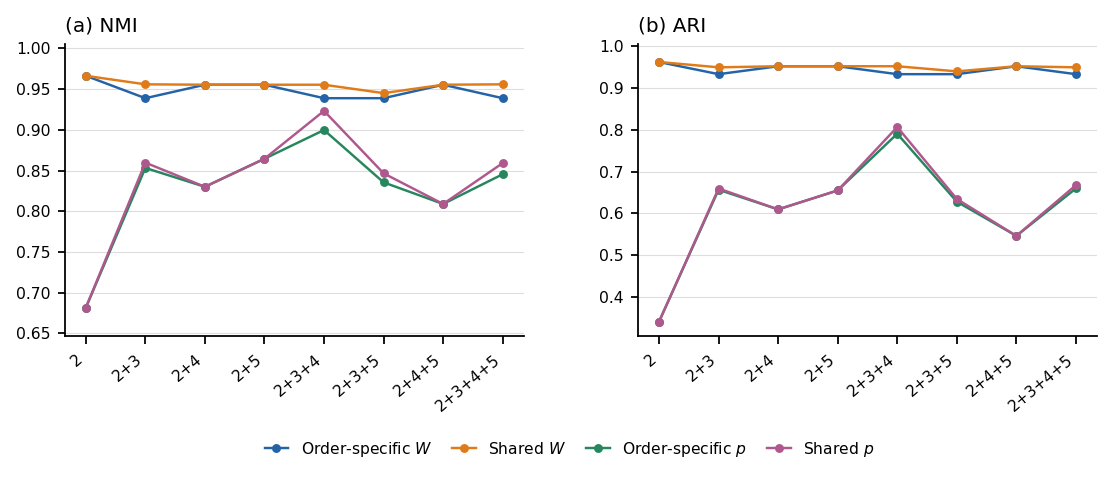

In [13]:
full_show_saved_png(FULL_RESULT_DIR / "metrics.png")


### 7.4 p and training W (appendix figures)

Retain the method × order grid: the full-order p figure is 4×4; training W shows only the two paper-w methods. Rows identify methods, the first row labels orders, and panels are lettered. Preserve the original numeric formatting and every value.

Overall titles, NMI, seed, and max-raw information are recorded outside the figure. Method descriptions, scale definitions, and sources are saved as `_caption.txt` and `_provenance.json`. A † beside a method row marks communities with no MAP-assigned nodes. Class names on axes indicate aligned display positions; original community IDs are in the alignment CSV.

The default color scale shows relative intensity (each matrix divided by its own maximum), while annotations retain raw parameter values. Set `FULL_AFFINITY_COLOR_SCALE="shared"` for a common absolute scale. Training $W=p/(c_0\beta_d/N)$ retains clipping effects; normalized W_shape is optional. Export PNG (600 dpi), PDF, and SVG.

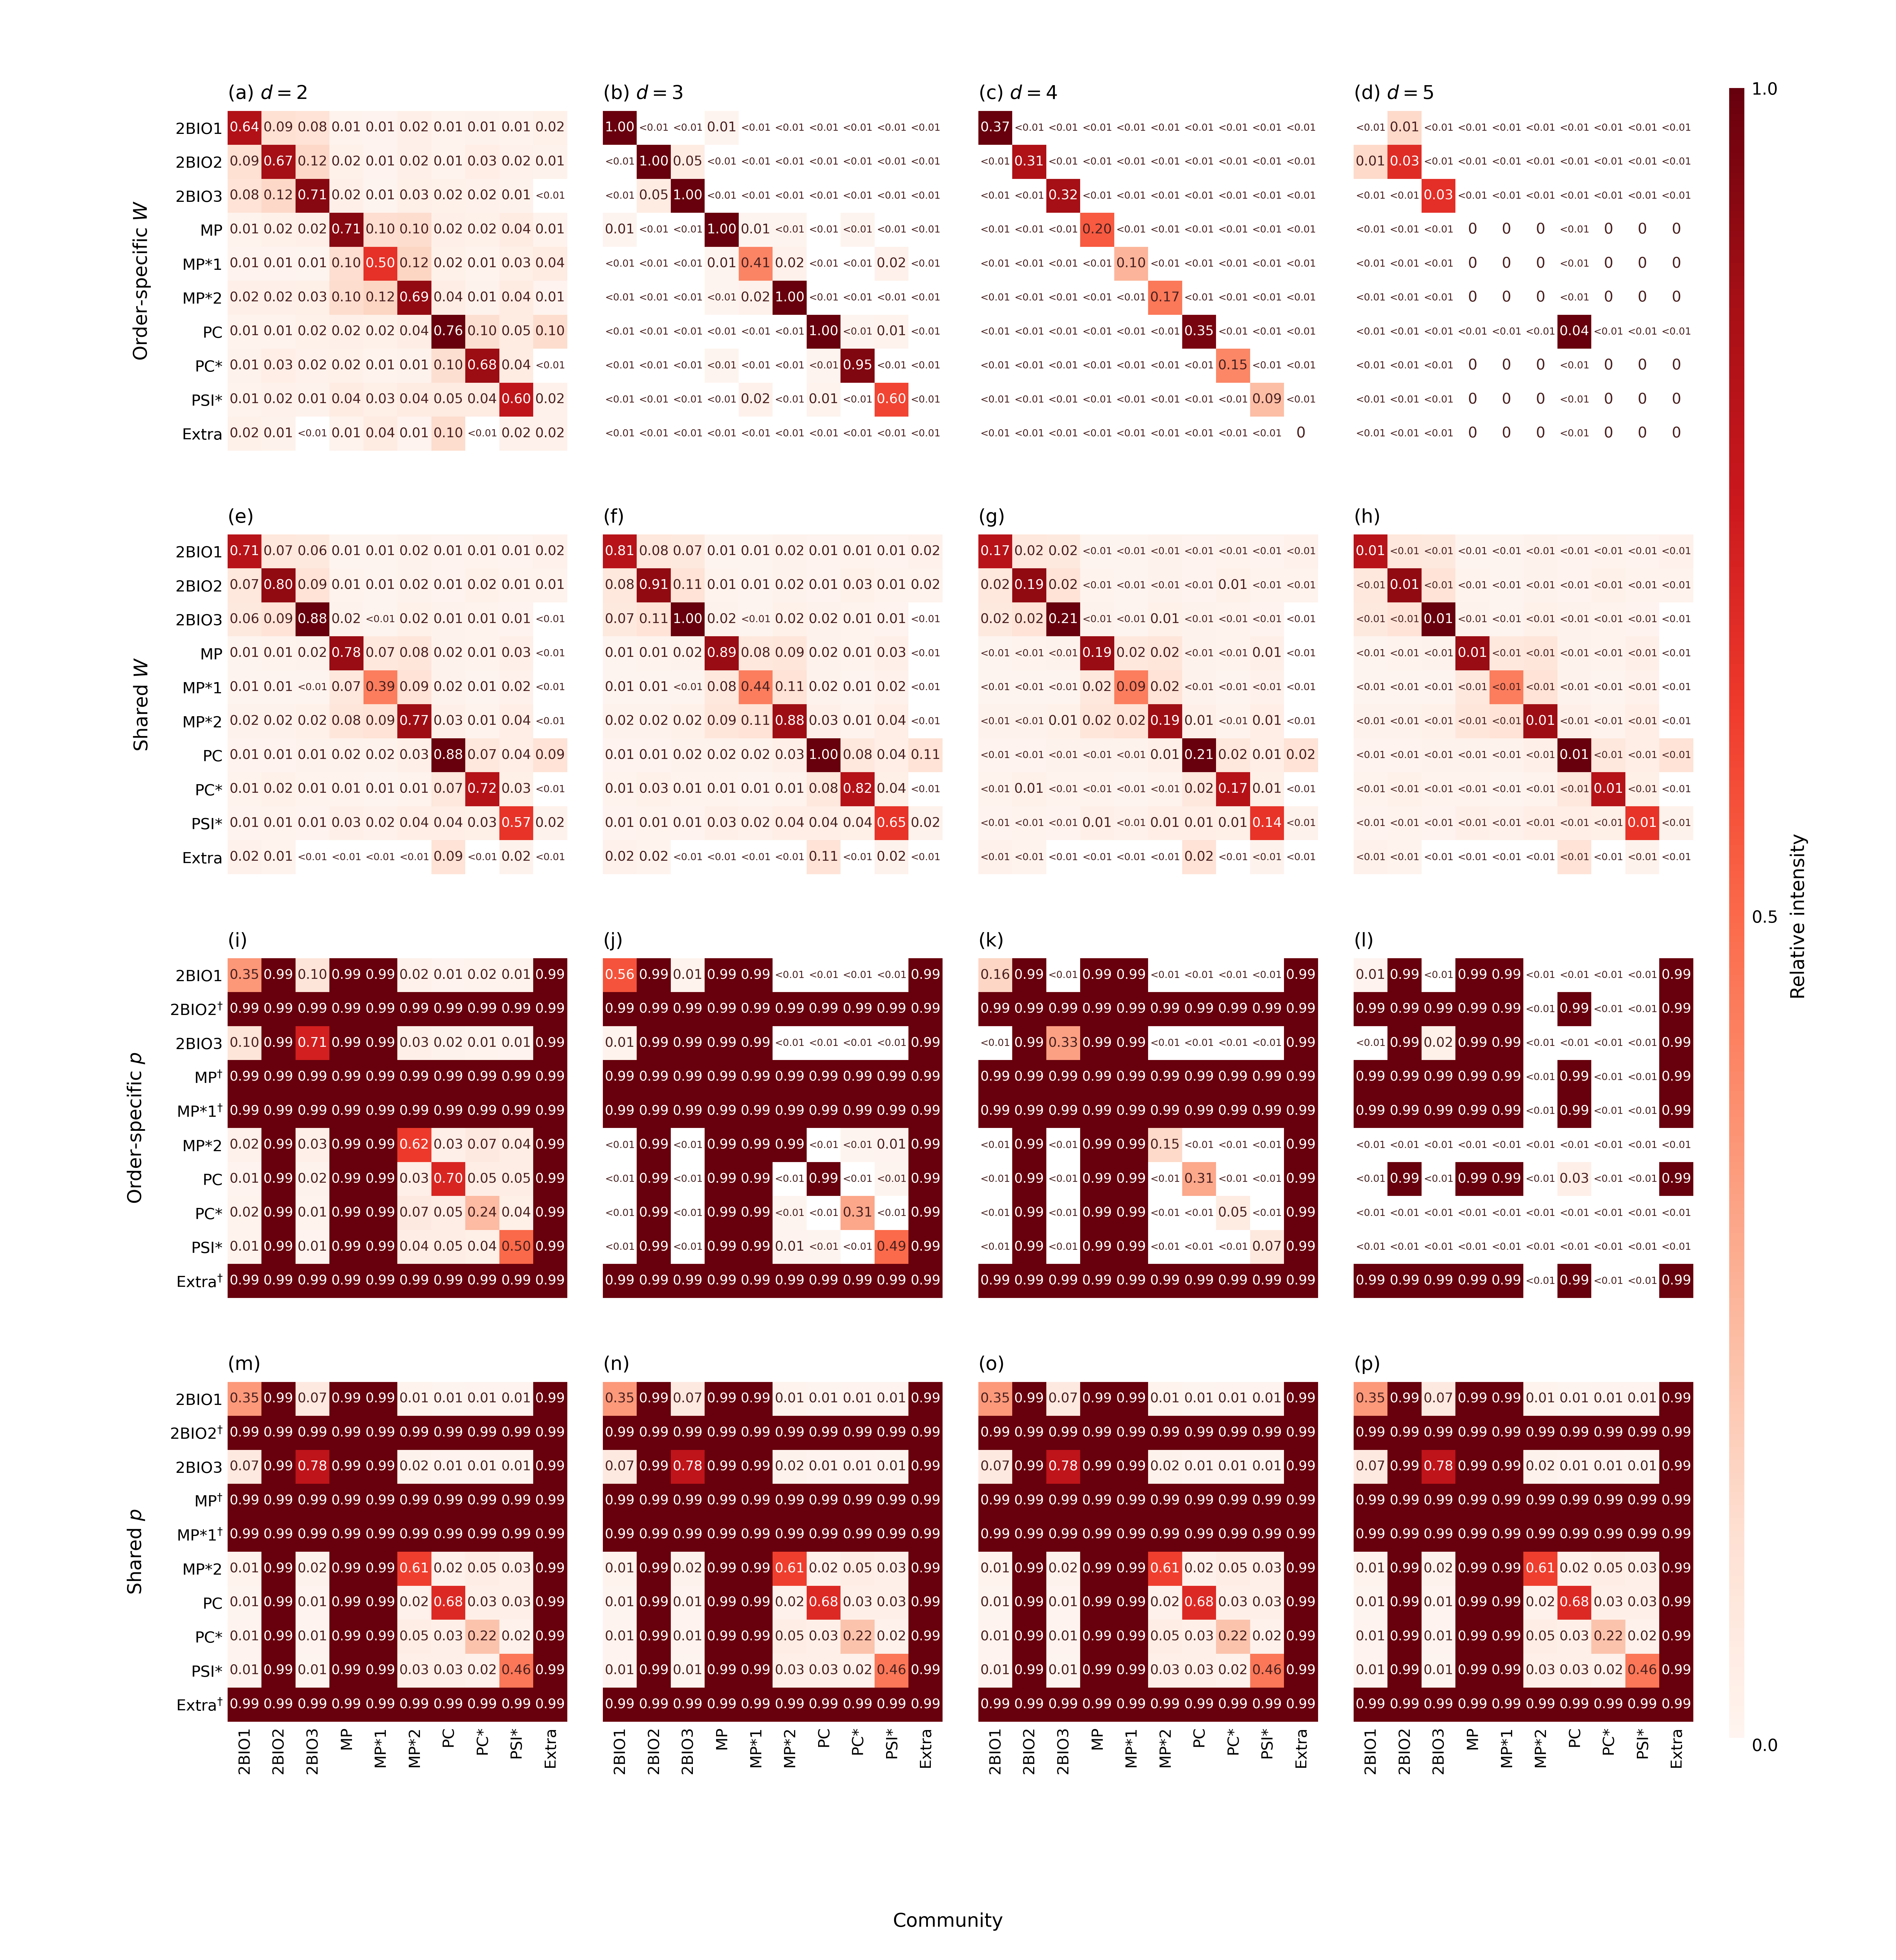

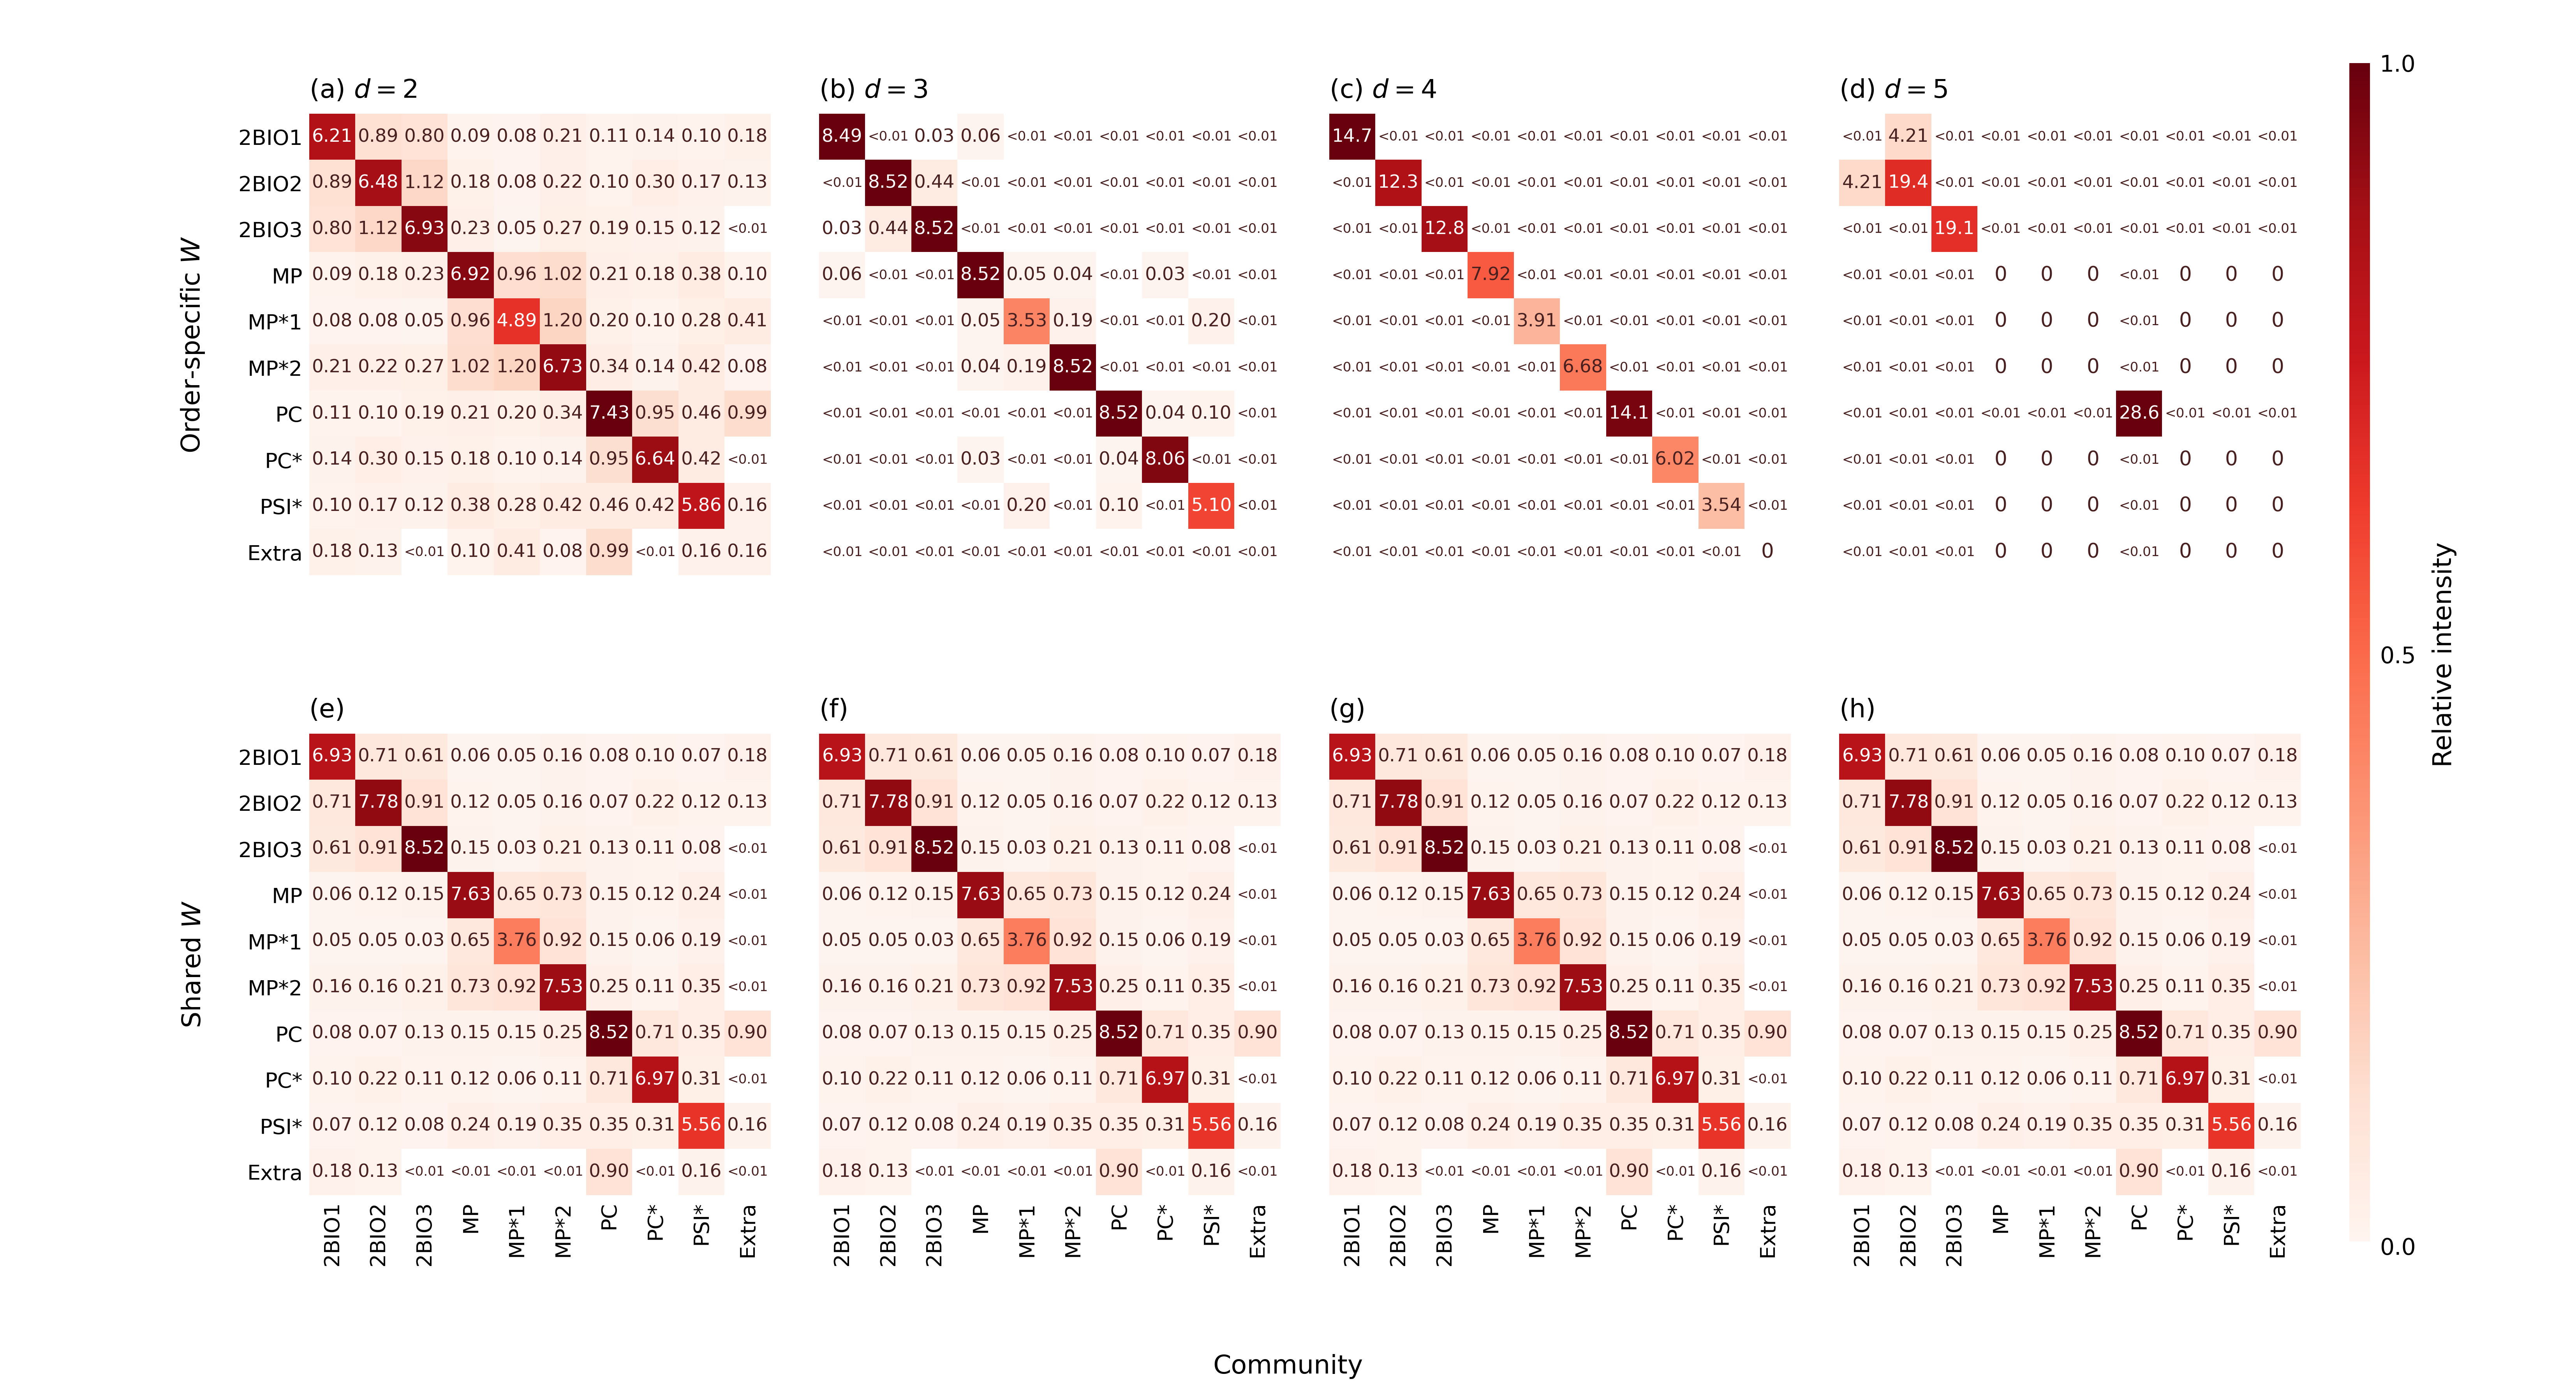

In [14]:
FULL_PLOT_SUFFIX = f"orders_{'-'.join(map(str, FULL_SHOW_ORDER_SET))}_seed_{FULL_SHOW_SEED}"
for kind in FULL_MATRIX_KINDS:
    full_show_saved_png(FULL_RESULT_DIR / f"affinity_{kind}_{FULL_PLOT_SUFFIX}.png")


### 7.5 Class–community soft posterior heatmaps

Entries are mean community posteriors within each true class, $M_{ca}=|V_c|^{-1}\sum_{i\in V_c}q_{i,\pi(a)}$, with each row summing to 1. Use the same fit-specific column permutation as the structural figures, retaining unmatched communities as `Extra`.

Provide a 180×156 mm 2×2 layout and a 280×82 mm 1×4 layout, sharing a 0–1 colorbar. Annotate every cell: values below 0.01 show <0.01; others use two decimals. Record order sets, alignment details, and experiment information in each figure's `_caption.txt`.

Export all eight groups as 600 dpi PNG, vector PDF/SVG, and complete probability CSV. Display the same selected group as above by default.

In [15]:
"""Class-by-community mean soft posteriors for the current W_compare_all fits."""
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize, LinearSegmentedColormap
from matplotlib.cm import ScalarMappable


def full_soft_membership_matrix(case):
    """Reuse this fit's existing class-based permutation, retaining all communities."""
    q = np.asarray(case['q'], dtype=float)
    labels = np.asarray(case['true_labels'])
    permutation = np.asarray(case['permutation'])
    classes = case['class_names']
    if (q.ndim != 2 or labels.shape != (len(q),) or not np.isfinite(q).all()
            or (q < 0).any() or not np.allclose(q.sum(axis=1), 1., atol=1e-9)):
        raise ValueError('Invalid normalized posterior or node-label dimensions.')
    K = q.shape[1]
    if (K < len(classes) or permutation.shape != (K,)
            or not np.array_equal(np.sort(permutation), np.arange(K))
            or not np.array_equal(np.unique(labels), np.arange(len(classes)))):
        raise ValueError('Invalid class ordering or complete community permutation.')
    aligned = q[:, permutation.astype(int)]
    matrix = np.stack([aligned[labels == i].mean(axis=0) for i in range(len(classes))])
    if not np.allclose(matrix.sum(axis=1), 1., atol=1e-9):
        raise ValueError('Each class row must sum to one.')
    return matrix


def full_soft_membership_average(cases):
    """Align each fit first; then average fits within the same mode and order set."""
    if not cases:
        raise ValueError('No saved fits selected.')
    first = cases[0]
    identity = (first['mode'], tuple(first['orders']), tuple(first['class_names']), first['q'].shape)
    for case in cases:
        current = (case['mode'], tuple(case['orders']), tuple(case['class_names']), case['q'].shape)
        if current != identity or not np.array_equal(case['true_labels'], first['true_labels']):
            raise ValueError('Only corresponding fits of the same method/order set can be averaged.')
    if len(cases) > 1 and first['q'].shape[1] - len(first['class_names']) > 1:
        raise ValueError('Multiple unmatched extra communities need an additional cross-fit alignment before averaging.')
    return np.mean(np.stack([full_soft_membership_matrix(case) for case in cases]), axis=0)


def full_soft_membership_figure(groups, layout='2x2'):
    """Paper and wide-row variants with compact labels and a shared color scale."""
    matrices = [full_soft_membership_average(group) for group in groups]
    class_names = groups[0][0]['class_names']
    count = len(groups)
    if layout not in {'2x2', '1x4'}:
        raise ValueError("layout must be '2x2' or '1x4'.")
    ncols = min(2, count) if layout == '2x2' else count
    nrows = int(np.ceil(count / ncols))
    width_mm = (180 if ncols == 2 else 90) if layout == '2x2' else 280
    height_mm = (156 if nrows == 2 else 86) if layout == '2x2' else 82
    fig = plt.figure(figsize=(width_mm / 25.4, height_mm / 25.4), facecolor='white')
    grid = fig.add_gridspec(nrows, ncols + 1, width_ratios=[*([1] * ncols), .045],
                            left=.105 if layout == '2x2' else .06,
                            right=.90 if layout == '2x2' else .94,
                            bottom=.11 if layout == '2x2' else .25,
                            top=.955 if layout == '2x2' else .91,
                            wspace=.12, hspace=.16)
    colors = plt.get_cmap('Reds')(np.linspace(0, 1, 256))
    colors[0] = [1, 1, 1, 1]
    cmap = LinearSegmentedColormap.from_list('membership_reds', colors)
    norm = Normalize(0, 1)
    method_titles = {'w-differ': r'Order-specific $W$', 'w-share': r'Shared $W$',
                     'p-differ': r'Order-specific $p$', 'p-share': r'Shared $p$'}
    for panel, (group, matrix) in enumerate(zip(groups, matrices)):
        panel_row, panel_column = divmod(panel, ncols)
        ax = fig.add_subplot(grid[panel_row, panel_column])
        K = matrix.shape[1]
        extra_count = K - len(class_names)
        extras = ['Extra'] if extra_count == 1 else [f'Extra {i + 1}' for i in range(extra_count)]
        ax.imshow(matrix, cmap=cmap, norm=norm, interpolation='nearest', aspect='equal')
        ax.set_xticks(np.arange(K), class_names + extras if panel_row == nrows - 1 else [''] * K,
                      rotation=90, fontsize=7.5)
        ax.set_yticks(np.arange(len(class_names)), class_names if panel_column == 0 else [''] * len(class_names),
                      fontsize=7.5)
        ax.set_title(f'({chr(ord("a") + panel)}) ' + method_titles.get(group[0]['mode'], group[0]['mode']),
                      fontsize=9, loc='left', pad=6)
        ax.set_xticks(np.arange(-.5, K, 1), minor=True)
        ax.set_yticks(np.arange(-.5, len(class_names), 1), minor=True)
        ax.grid(which='minor', color='white', linewidth=.4)
        ax.tick_params(which='both', length=0)
        for spine in ax.spines.values():
            spine.set_visible(False)
        for row in range(len(class_names)):
            for column in range(K):
                value = matrix[row, column]
                label = '<0.01' if value < .01 else f'{value:.2f}'
                fontsize = (5.5 if layout == '2x2' else 4.8) if value < .01 else (7 if layout == '2x2' else 6.2)
                ax.text(column, row, label,
                        ha='center', va='center', fontsize=fontsize,
                        color='white' if value >= .5 else '#202020')
    colorbar = fig.colorbar(ScalarMappable(norm=norm, cmap=cmap), cax=fig.add_subplot(grid[:, -1]),
                            ticks=np.linspace(0, 1, 6))
    colorbar.outline.set_visible(False)
    colorbar.ax.tick_params(labelsize=7.5, length=0, pad=3)
    colorbar.set_label('Mean posterior probability', fontsize=8, labelpad=6)
    fig.supxlabel('Community', fontsize=8, y=.015)
    fig.supylabel('Class', fontsize=8, x=.015)
    return fig, matrices


def full_save_soft_membership_plots(cases, output_dir, layouts=('2x2', '1x4')):
    """Save all eight order sets, keeping the four W/p methods as separate panels."""
    output_dir = Path(output_dir).expanduser().resolve()
    output_dir.mkdir(parents=True, exist_ok=True)
    modes = ['w-differ', 'w-share', 'p-differ', 'p-share']
    orders_list = sorted({tuple(case['orders']) for case in cases}, key=lambda value: (len(value), value))
    records, fit_records, sources, figure_paths = [], [], [], []
    for orders in orders_list:
        groups = [[case for case in cases if case['mode'] == mode and tuple(case['orders']) == orders] for mode in modes]
        if any(not group for group in groups):
            raise ValueError(f'Missing method in order set {orders}.')
        order_text = ', '.join(map(str, orders))
        caption = (
            'Class-community memberships inferred from the high-school hypergraph using orders '
            '{' + order_text + '}. Panels show (a) order-specific W, (b) shared W, '
            '(c) order-specific p, and (d) shared p. Each cell is the community posterior '
            'probability averaged over nodes in one observed class; each row sums to one. '
            'Community labels are matched to class labels only for visualization, and Extra '
            'denotes an unmatched community. All panels share the same probability scale. '
            'Shared W uses a common structural shape with order-dependent scales, whereas '
            'shared p uses one complete affinity matrix across orders. '
            'All cells are annotated: values below 0.01 are labelled <0.01; others use two decimal places. '
            + ('One fitted realization per method is shown.\n' if all(len(group) == 1 for group in groups)
               else 'Saved fits are aligned before averaging within each method.\n')
        )
        for layout in layouts:
            with plt.rc_context({'font.family': 'DejaVu Sans', 'pdf.fonttype': 42, 'ps.fonttype': 42,
                                 'svg.fonttype': 'none'}):
                fig, matrices = full_soft_membership_figure(groups, layout=layout)
                stem = 'class_membership_orders_' + '-'.join(map(str, orders))
                if layout != '2x2':
                    stem += '_' + layout
                for extension in ['png', 'pdf', 'svg']:
                    path = output_dir / f'{stem}.{extension}'
                    # Preserve physical dimensions in both vector and raster files.
                    fig.savefig(path, dpi=600, facecolor='white')
                    figure_paths.append(str(path))
                plt.close(fig)
            (output_dir / f'{stem}_caption.txt').write_text(caption, encoding='utf-8')
        for group, matrix in zip(groups, matrices):
            classes, K = group[0]['class_names'], matrix.shape[1]
            extras = ['Extra'] if K - len(classes) == 1 else [f'Extra {i + 1}' for i in range(K - len(classes))]
            names = classes + extras
            for row, column in np.ndindex(matrix.shape):
                records.append({'mode': group[0]['mode'], 'order_set': '+'.join(map(str, orders)),
                                'n_fits': len(group), 'class': classes[row], 'matched_column': column,
                                'community_position': names[column], 'mean_soft_probability': matrix[row, column]})
            for case in group:
                per_fit = full_soft_membership_matrix(case)
                sources.append({'mode': case['mode'], 'order_set': '+'.join(map(str, orders)),
                                'seed': int(case['seed']), 'raw_path': case['raw_path'],
                                'community_permutation': list(map(int, case['permutation']))})
                for row, column in np.ndindex(per_fit.shape):
                    fit_records.append({'mode': case['mode'], 'order_set': '+'.join(map(str, orders)),
                                        'seed': int(case['seed']), 'class': classes[row], 'matched_column': column,
                                        'original_community': int(case['permutation'][column]),
                                        'soft_probability': per_fit[row, column]})
    frame, per_fit_frame = pd.DataFrame(records), pd.DataFrame(fit_records)
    frame.to_csv(output_dir / 'class_membership_mean.csv', index=False, encoding='utf-8-sig')
    per_fit_frame.to_csv(output_dir / 'class_membership_by_fit.csv', index=False, encoding='utf-8-sig')
    provenance = {'input': 'Current W_compare_all saved fits only',
                  'definition': 'M[c,a] = mean(q[i,permutation[a]] for nodes i in true class c)',
                  'alignment': 'Reuse exactly the same per-fit permutation as the affinity figures.',
                  'averaging': 'Within each method/order set, align each saved fit before averaging.',
                  'color_scale': 'Shared absolute probability 0..1; no per-panel normalization.',
                  'paper_style': {'layouts': {'2x2': [180, 156], '1x4': [280, 82]},
                                  'png_dpi': 600, 'vector_formats': ['pdf', 'svg'],
                                  'all_cells_annotated': True,
                                  'small_value_label': '<0.01',
                                  'panel_titles': 'method names only; experimental details in caption files'},
                  'extra_communities': 'Retained; matched column names are display positions, not known labels used for fitting.',
                  'sources': sources}
    (output_dir / 'provenance.json').write_text(json.dumps(provenance, ensure_ascii=False, indent=2), encoding='utf-8')
    print(f'Soft class/community plots: {len(orders_list)} order sets, {len(modes)} methods, {len(cases)} saved fits.')
    print(f'Outputs: {output_dir}')
    return {'output_dir': output_dir, 'figure_paths': figure_paths, 'means': frame, 'by_fit': per_fit_frame}


In [16]:
# Change to (2, 3), (2, 4), etc.; all eight groups are still saved.
FULL_SOFT_SHOW_ORDER_SET = FULL_SHOW_ORDER_SET
if "FULL_REPORT" not in globals():
    raise RuntimeError("请先运行第7.2节，读取当前 W_compare_all 的拟合结果。")

FULL_SOFT_REPORT = full_save_soft_membership_plots(
    FULL_REPORT["cases"], FULL_RESULT_DIR / "class_membership",
)


Soft class/community plots: 8 order sets, 4 methods, 32 saved fits.
Outputs: D:\codex_data\2026-10-19\wo\outputs\D-HySBM-GitHub\outputs\highschool_full_fit_analysis\20261019_133252_788711\class_membership


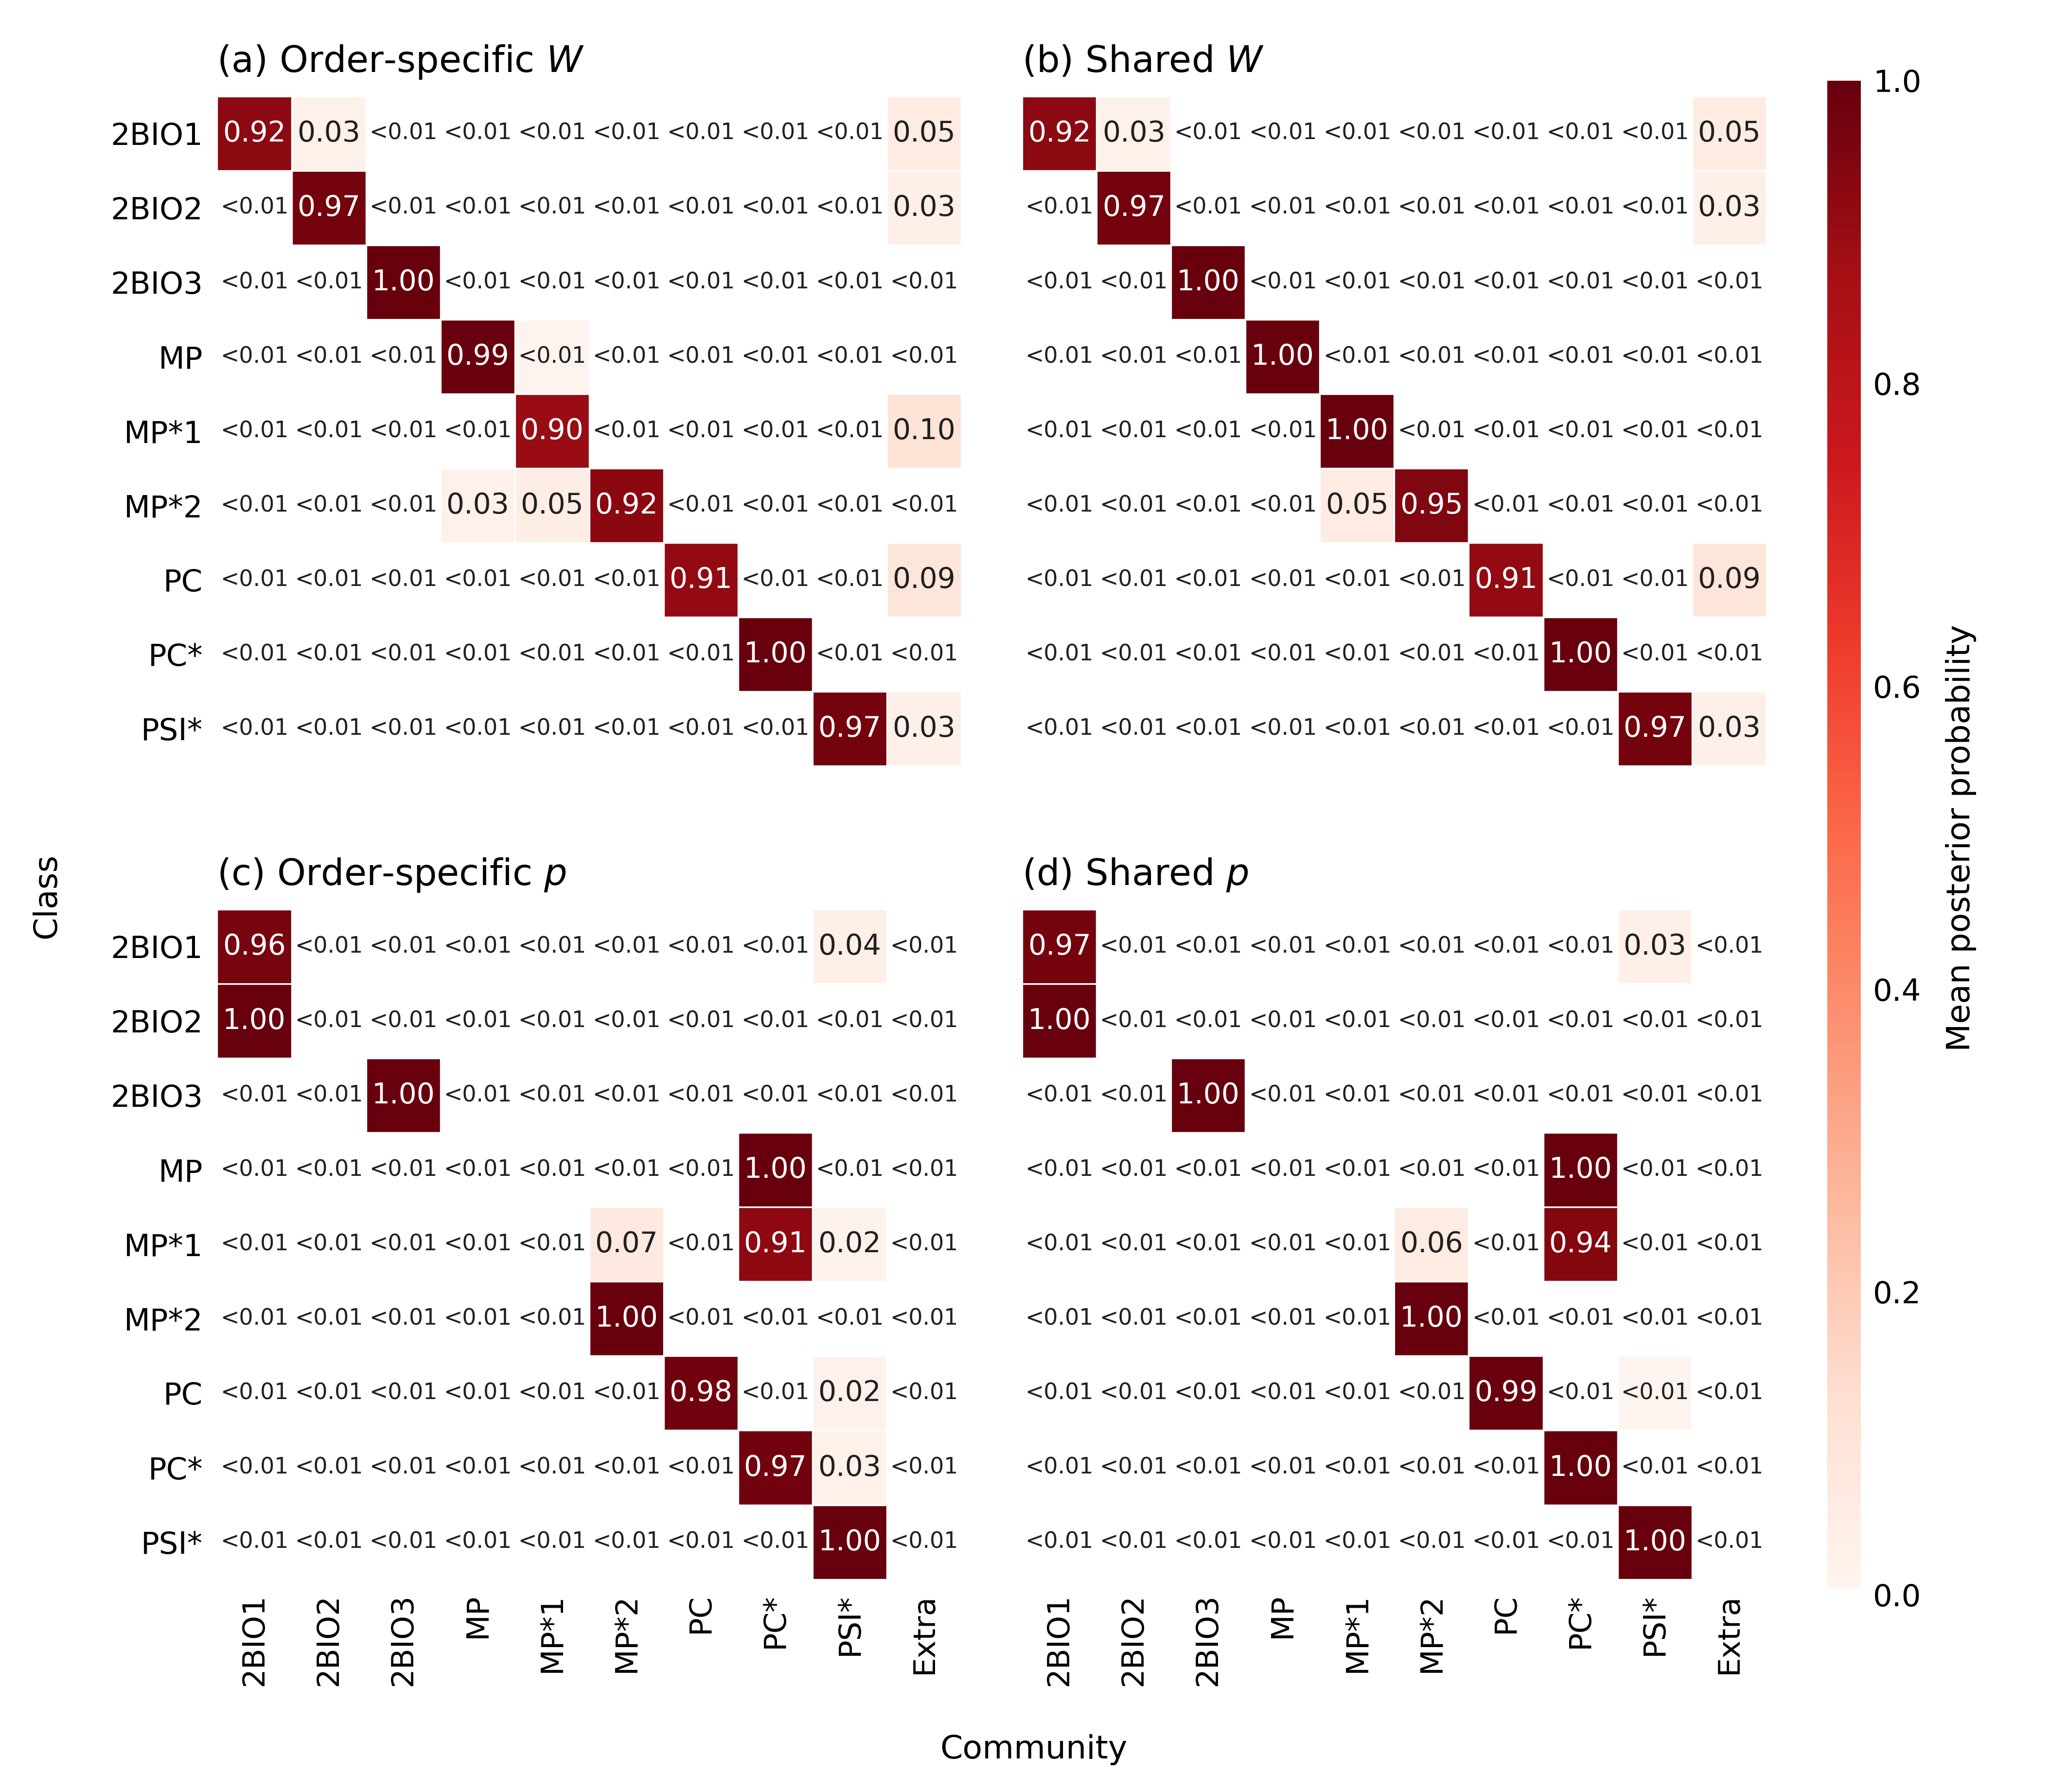

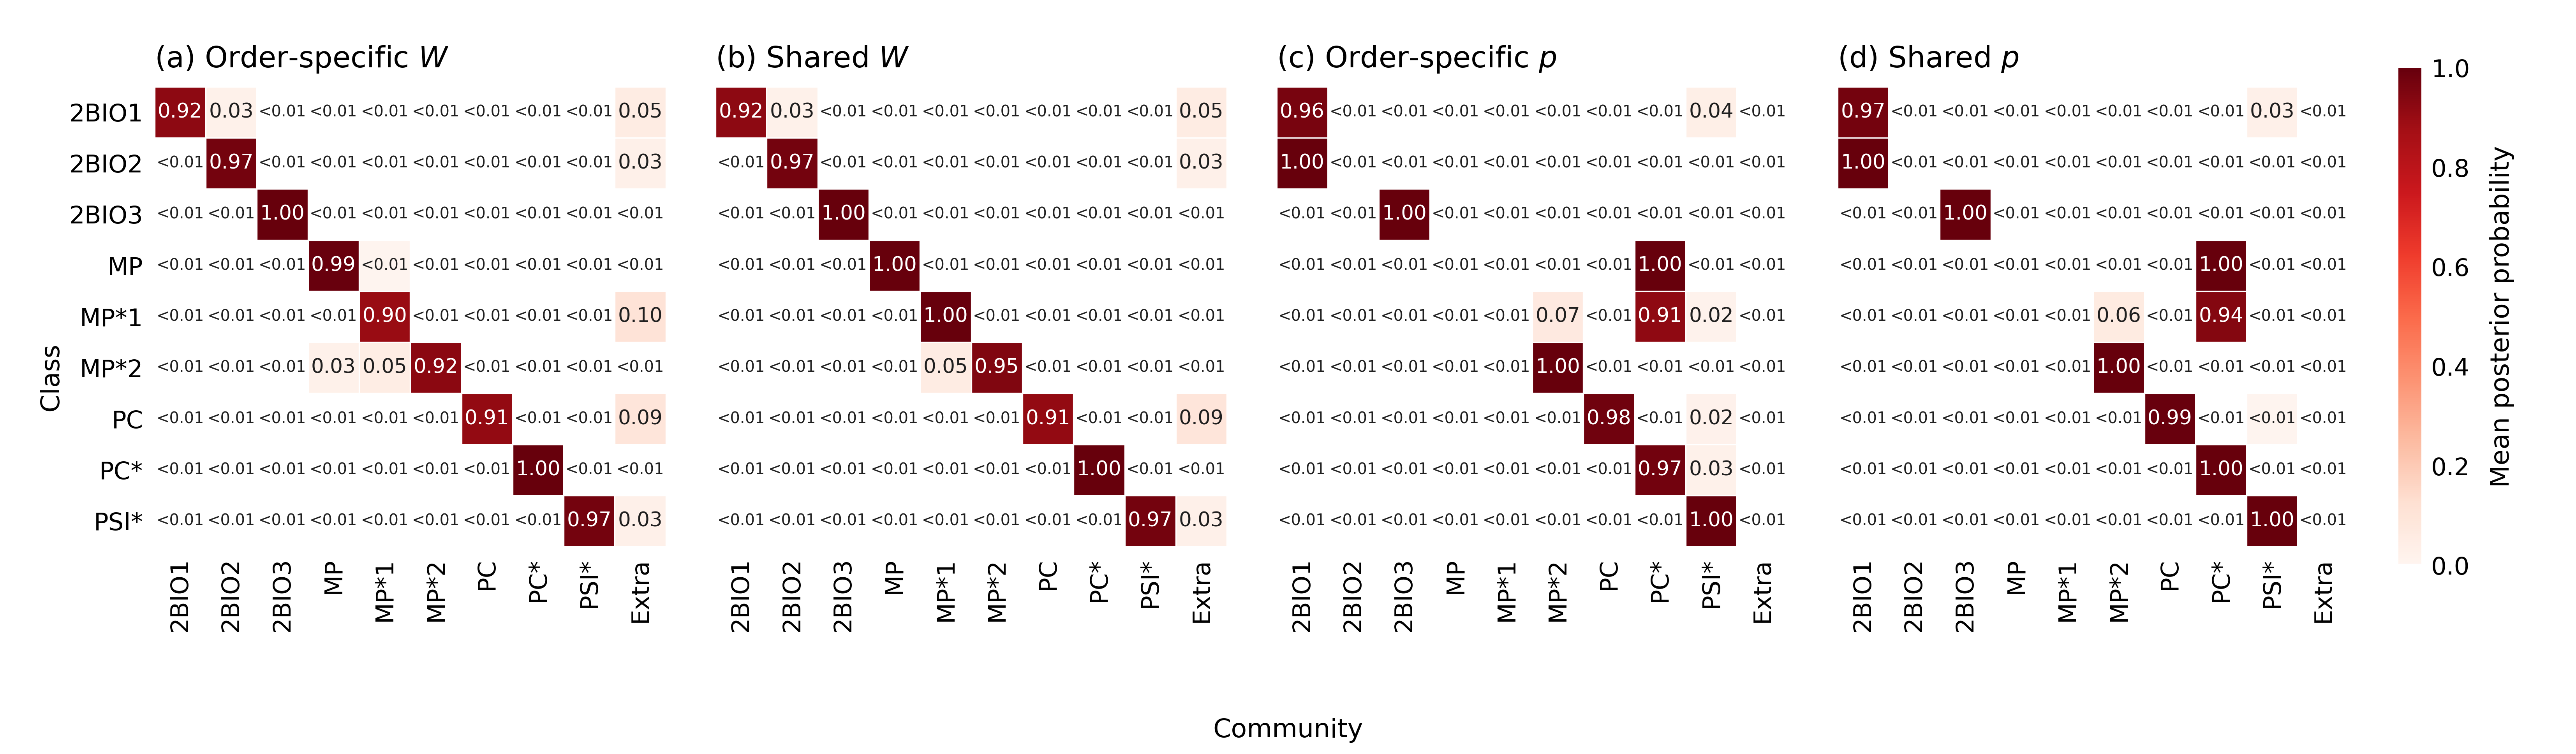

In [17]:
FULL_SOFT_STEM = "class_membership_orders_" + "-".join(map(str, FULL_SOFT_SHOW_ORDER_SET))
for suffix in ["", "_1x4"]:
    full_show_saved_png(FULL_SOFT_REPORT["output_dir"] / f"{FULL_SOFT_STEM}{suffix}.png")


### 7.6 Exported files

Outputs include complete metric/difference CSV files, p/W matrix entries, soft posteriors, captions, and provenance. Soft-posterior PDF/SVG files support publication layout and editing; PNG files use 600 dpi.

In [18]:
print("结果目录：", FULL_RESULT_DIR)
print("论文软后验图：", FULL_SOFT_REPORT["output_dir"])


结果目录： D:\codex_data\2026-10-19\wo\outputs\D-HySBM-GitHub\outputs\highschool_full_fit_analysis\20261019_133252_788711
论文软后验图： D:\codex_data\2026-10-19\wo\outputs\D-HySBM-GitHub\outputs\highschool_full_fit_analysis\20261019_133252_788711\class_membership


## 8. Standalone paper figures: aggregate AUC, NMI, selected order sets, and class alignment

Use `auc_report` from Section 4, `FULL_REPORT` from Section 7.2, and soft-posterior functions from Section 7.5. Read saved fits without retraining. Export each figure separately as PNG (600 dpi), vector PDF, and SVG. AUC and NMI each retain four curves: Order-specific W, Shared W, Order-specific p, and Shared p.

Within each fold, weight order-specific AUC by positive test-hyperedge counts, then compute the five-fold mean and sample standard deviation:

$$\mathrm{AUC}_{\mathrm w,f}=\frac{\sum_{d\in\mathcal D}M_{d,f}\,\mathrm{AUC}_{d,f}}{\sum_{d\in\mathcal D}M_{d,f}}.$$

Here $M_{d,f}$ counts order-$d$ positive test hyperedges in fold $f$. Weights and evaluation orders depend on the retained order set. All AUC curves and AUC-based selections use this aggregate metric.
NMI comes from separate full-data fits, currently with outer seed 234 only, so no error bars are shown. Selected configurations are listed as retained order sets with scores rather than binary grids.

In [19]:
from pathlib import Path

# Adjust these options without changing the original grids or computed results.
PAPER_OUTPUT_DIR = Path(PROJECT_DIR) / "outputs" / "realdata_individual"
PAPER_ORDER_SETS = None  # None includes all eight retained order sets; alternatively use [(2,), (2, 3), ...].
PAPER_MEMBERSHIP_ORDER_SET = tuple(FULL_SHOW_ORDER_SET)
PAPER_MEMBERSHIP_SEED = int(FULL_SHOW_SEED)
PAPER_SHOW_FIGURES = True

# Paper-layout controls; individual plot calls can override them.
PAPER_SHOW_LEGEND = True            # Legend for the four curves; False hides it.
PAPER_LEGEND_LOC = "lower right"    # Other choices include "upper left" and "best".
PAPER_SHOW_TITLES = False           # In-figure title.
PAPER_SHOW_AXIS_LABELS = True       # Axis labels.
PAPER_SHOW_PANEL_LABELS = True      # (a)、(b)、(c)、(d)
PAPER_SHOW_COLORBAR = True          # Colorbar for the paper's right heatmap.


if "auc_report" not in globals() or "FULL_REPORT" not in globals():
    raise RuntimeError("请先运行第4节与第7.2节，载入CV和全量拟合结果。")
if "full_soft_membership_matrix" not in globals():
    raise RuntimeError("请先运行第7.5节的软后验计算函数单元。")

In [20]:
"""Separate publication figures, reusing the saved CV and full-data reports."""
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, Normalize, LinearSegmentedColormap


PAPER_METHODS = ("w-differ", "w-share", "p-differ", "p-share")
PAPER_STYLE = {
    "w-differ": (r"Order-specific $W$", "#2463a6", "o", "-"),
    "w-share": (r"Shared $W$", "#df7b18", "s", "-"),
    "p-differ": (r"Order-specific $p$", "#27865d", "^", "--"),
    "p-share": (r"Shared $p$", "#ae588d", "D", "--"),
}


def paper_order_label(orders):
    return "{" + ",".join(map(str, orders)) + "}"


def paper_prepare_data(cv_report, full_report, order_sets=None):
    """Use positive-count-weighted CV AUC and separate full-data NMI."""
    auc = pd.DataFrame(cv_report["aggregate_summary"])
    if auc.empty:
        raise ValueError("No aggregate held-out AUC results.")
    auc["orders"] = auc["train_orders"].map(lambda values: tuple(map(int, values)))
    auc = auc.loc[auc["model"].isin(PAPER_METHODS)].copy()
    if auc.duplicated(["model", "orders"]).any():
        raise ValueError("Duplicate model/order-set entries in CV AUC summary.")

    metrics = full_report["tables"]["metrics"].copy()
    metrics["orders"] = metrics["order_set"].map(
        lambda value: tuple(map(int, str(value).split("+"))))
    metrics = metrics.loc[metrics["mode"].isin(PAPER_METHODS)].copy()
    if metrics.duplicated(["mode", "orders", "seed"]).any():
        raise ValueError("Duplicate full-data fits for a method/order set/outer seed.")
    nmi = metrics.groupby(["mode", "orders"], sort=False)["nmi"].agg(
        nmi_mean="mean", nmi_std="std", n_seeds="count").reset_index()

    available = {tuple(values) for values in cv_report["order_sets"]}
    chosen = (sorted(available, key=lambda values: (len(values), values))
              if order_sets is None else [tuple(map(int, values)) for values in order_sets])
    if not chosen or len(set(chosen)) != len(chosen) or set(chosen) - available:
        raise ValueError("PAPER_ORDER_SETS is empty, duplicated, or missing aggregate CV results.")
    for mode in PAPER_METHODS:
        missing_auc = set(chosen) - set(auc.loc[auc["model"] == mode, "orders"])
        missing_nmi = set(chosen) - set(nmi.loc[nmi["mode"] == mode, "orders"])
        if missing_auc or missing_nmi:
            raise ValueError(f"Missing {mode} results: AUC {missing_auc}, NMI {missing_nmi}.")
    auc = auc.loc[auc["orders"].isin(chosen)].copy()
    nmi = nmi.loc[nmi["orders"].isin(chosen)].copy()
    if not np.isfinite(auc[["weighted_auc_mean", "weighted_auc_std"]].to_numpy(float)).all():
        raise ValueError("Nonfinite CV AUC mean or SD.")
    if not np.isfinite(nmi["nmi_mean"].to_numpy(float)).all():
        raise ValueError("Nonfinite NMI.")
    return {"auc": auc, "nmi": nmi, "orders": chosen,
            "auc_metric": "weighted_auc", "full_metrics": metrics}


def paper_save_figure(fig, output_dir, stem, caption, data=None, show=True, *, bbox_inches="tight"):
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    with plt.rc_context({"pdf.fonttype": 42, "ps.fonttype": 42,
                         "svg.fonttype": "none", "font.family": "DejaVu Sans"}):
        for suffix in ("png", "pdf", "svg"):
            fig.savefig(output_dir / f"{stem}.{suffix}", dpi=600,
                        bbox_inches=bbox_inches, facecolor="white")
    (output_dir / f"{stem}_caption.txt").write_text(caption + "\n", encoding="utf-8")
    if data is not None:
        data.to_csv(output_dir / f"{stem}_data.csv", index=False, encoding="utf-8-sig")
    if show:
        from IPython.display import display
        display(fig)
    plt.close(fig)
    return {suffix: output_dir / f"{stem}.{suffix}" for suffix in ("png", "pdf", "svg")}


def paper_metric_plot(data, metric, output_dir, show=True, *,
                      show_legend=True, legend_loc="lower right", legend_ncol=2,
                      legend_kwargs=None, show_title=False, title=None,
                      show_axis_labels=True, show_grid=True, panel_label=None):
    """One four-curve figure, with independent legend/title/label switches."""
    if metric not in {"auc", "nmi"}:
        raise ValueError("metric must be 'auc' or 'nmi'.")
    orders = data["orders"]
    x = np.arange(len(orders), dtype=float)
    fig, ax = plt.subplots(figsize=(6.8, 4.5), facecolor="white")
    for offset, mode in zip(np.linspace(-.075, .075, len(PAPER_METHODS)), PAPER_METHODS):
        label, color, marker, linestyle = PAPER_STYLE[mode]
        frame = data[metric]
        mode_column = "model" if metric == "auc" else "mode"
        lookup = {row["orders"]: row for row in frame.loc[frame[mode_column] == mode].to_dict("records")}
        rows = [lookup[values] for values in orders]
        means = np.array([row["weighted_auc_mean" if metric == "auc" else "nmi_mean"] for row in rows])
        errors = np.array([row["weighted_auc_std"] if metric == "auc" else
                           (row["nmi_std"] if row["n_seeds"] > 1 else np.nan) for row in rows])
        options = dict(color=color, marker=marker, linestyle=linestyle,
                       linewidth=1.4, markersize=4.5, label=label)
        if np.isfinite(errors).any():
            ax.errorbar(x + offset, means, yerr=errors, capsize=3,
                        elinewidth=.9, capthick=.9, **options)
        else:
            ax.plot(x + offset, means, **options)
    ax.set_xticks(x, [paper_order_label(values) for values in orders],
                  rotation=35, ha="right", fontsize=9)
    if show_axis_labels:
        ax.set_xlabel(r"Retained orders $\mathcal{D}$", fontsize=11)
        ax.set_ylabel("Weighted held-out AUC" if metric == "auc" else "NMI", fontsize=11)
    ax.tick_params(axis="y", labelsize=10)
    if show_grid:
        ax.grid(axis="y", alpha=.22, linewidth=.6)
    ax.set_xlim(-.35, len(orders) - .65)
    ax.margins(y=.15)
    if show_legend:
        options = dict(loc=legend_loc, ncol=legend_ncol, fontsize=9,
                       frameon=True, framealpha=.9, facecolor="white",
                       columnspacing=1.2, handlelength=2.6)
        options.update(legend_kwargs or {})
        ax.legend(**options)
    if show_title:
        ax.set_title(title if title is not None else ("Weighted AUC" if metric == "auc" else "NMI"),
                     fontsize=11, pad=8)
    if panel_label:
        ax.text(-.085, 1.035, panel_label, transform=ax.transAxes,
                ha="left", va="bottom", fontsize=13, clip_on=False)
    fig.tight_layout(pad=.8)
    if metric == "auc":
        stem = "auc_weighted_four_methods"
        caption = ("Weighted held-out AUC for four affinity parameterizations across retained training-order "
                   "sets. Within each fold, within-order AUCs are weighted by held-out positive counts. "
                   "Seeds are averaged within folds before the five-fold mean and sample SD (ddof=1). "
                   "Weights and evaluated orders follow each retained-order set. Connecting lines are visual guides.")
    else:
        stem = "nmi_four_methods"
        caption = ("Normalized mutual information (arithmetic normalization) between MAP communities and class "
                   "metadata, evaluated on separately saved full-data fits. Sample-SD error bars appear only "
                   "with at least two outer seeds. Current single-seed results have no error bars. "
                   "Internal restarts are not independent repetitions. Connecting lines are visual guides.")
    return paper_save_figure(fig, output_dir, stem, caption, data[metric], show)



def paper_selected_order_table(data, output_dir, tie_atol=1e-12):
    """Report separate maxima; resolve display ties by fewer orders, then lexicographically."""
    records = []
    for mode in PAPER_METHODS:
        auc_rows = data["auc"].loc[data["auc"]["model"] == mode].to_dict("records")
        nmi_rows = data["nmi"].loc[data["nmi"]["mode"] == mode].to_dict("records")
        nmi_lookup = {r["orders"]: r for r in nmi_rows}
        auc_max = max(r["weighted_auc_mean"] for r in auc_rows)
        nmi_max = max(r["nmi_mean"] for r in nmi_rows)
        auc_ties = sorted([r["orders"] for r in auc_rows if np.isclose(r["weighted_auc_mean"], auc_max, rtol=0, atol=tie_atol)],
                          key=lambda values: (len(values), values))
        nmi_ties = sorted([r["orders"] for r in nmi_rows if np.isclose(r["nmi_mean"], nmi_max, rtol=0, atol=tie_atol)],
                          key=lambda values: (len(values), values))
        selected_auc, selected_nmi = auc_ties[0], nmi_ties[0]
        auc_row = next(r for r in auc_rows if r["orders"] == selected_auc)
        records.append({
            "model": mode, "auc_selected_orders": selected_auc,
            "cv_auc_mean": auc_row["weighted_auc_mean"], "cv_auc_std": auc_row["weighted_auc_std"],
            "full_nmi_at_auc_selected_orders": nmi_lookup[selected_auc]["nmi_mean"],
            "nmi_selected_orders": selected_nmi, "full_nmi_max": nmi_max,
            "auc_tied_order_sets": " | ".join(map(paper_order_label, auc_ties)),
            "nmi_tied_order_sets": " | ".join(map(paper_order_label, nmi_ties)),
        })
    frame = pd.DataFrame(records)
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    frame.to_csv(output_dir / "selected_order_sets.csv", index=False, encoding="utf-8-sig")
    method_tex = {"w-differ": r"Order-specific $W$", "w-share": r"Shared $W$",
                  "p-differ": r"Order-specific $p$", "p-share": r"Shared $p$"}
    def orders_tex(values):
        return r"$\{" + ",".join(map(str, values)) + r"\}$"
    lines = [r"\begin{tabular}{lccccc}", r"\hline",
             r"Method & AUC-selected $\mathcal D$ & Weighted AUC & NMI at this $\mathcal D$ & NMI-selected $\mathcal D$ & NMI \\",
             r"\hline"]
    for row in records:
        values = [method_tex[row["model"]], orders_tex(row["auc_selected_orders"]),
                  f"${row['cv_auc_mean']:.3f} \\pm {row['cv_auc_std']:.3f}$",
                  f"{row['full_nmi_at_auc_selected_orders']:.3f}", orders_tex(row["nmi_selected_orders"]),
                  f"{row['full_nmi_max']:.3f}"]
        lines.append(" & ".join(values) + r" \\")
    lines += [r"\hline", r"\end{tabular}"]
    (output_dir / "selected_order_sets.tex").write_text("\n".join(lines) + "\n", encoding="utf-8")
    (output_dir / "selected_order_sets_caption.txt").write_text(
        "Order sets with the largest mean positive-count-weighted CV AUC and largest mean full-data NMI "
        "among the evaluated candidates. These are different selection criteria, not a claim of a jointly "
        "optimal model or an independent test estimate after selection. The NMI at the AUC-selected order "
        "set is from a separate full-data fit, not from the CV fits. All numerical ties are recorded in CSV; "
        "the display chooses fewer retained orders and then lexicographic order. These are retained order "
        "sets, not inferred partitions of orders into sharing groups.\n", encoding="utf-8")
    return frame


def paper_selected_order_plot(selection, data, criterion, output_dir, show=True):
    """State each selected order set and score directly, without a binary inclusion grid."""
    if criterion not in {"auc", "nmi"}:
        raise ValueError("criterion must be 'auc' or 'nmi'.")
    column = "auc_selected_orders" if criterion == "auc" else "nmi_selected_orders"
    lookup = selection.set_index("model")
    rows = []
    for mode in PAPER_METHODS:
        result = lookup.loc[mode]
        score = (f"{result['cv_auc_mean']:.3f} ± {result['cv_auc_std']:.3f}"
                 if criterion == "auc" else f"{result['full_nmi_max']:.3f}")
        rows.append([PAPER_STYLE[mode][0], paper_order_label(result[column]), score])
    fig, ax = plt.subplots(figsize=(7.1, 2.35), facecolor="white")
    ax.set_axis_off()
    table = ax.table(cellText=rows,
                     colLabels=["Method", r"Selected orders $\mathcal{D}$",
                                "Weighted AUC" if criterion == "auc" else "NMI"],
                     colWidths=[.39, .31, .30], cellLoc="center", bbox=[0, .02, 1, .96])
    table.auto_set_font_size(False)
    table.set_fontsize(11)
    for (row, col), cell in table.get_celld().items():
        cell.visible_edges = "horizontal"
        cell.set_edgecolor("#cccccc")
        cell.set_linewidth(.55)
        if row == 0:
            cell.set_text_props(weight="bold")
            cell.set_edgecolor("#555555")
            cell.set_linewidth(.85)
        if col == 0:
            cell.set_text_props(ha="left")
    fig.tight_layout(pad=.6)
    stem = "selected_orders_auc_weighted" if criterion == "auc" else "selected_orders_nmi"
    caption = (f"Retained order sets with the highest {'mean weighted CV AUC' if criterion == 'auc' else 'mean full-data NMI'} "
               "among the evaluated candidates, shown directly alongside their scores. AUC uncertainty "
               "is the five-fold sample standard deviation. NMI is from the separately fitted full data; "
               "the current single-seed NMI has no uncertainty estimate. All numerical ties are listed "
               "in selected_order_sets.csv; the display chooses fewer orders and then lexicographic "
               "order. These are retained order sets, not partitions into sharing groups.")
    return paper_save_figure(fig, output_dir, stem, caption, selection, show)


def paper_membership_plot(cases, mode, orders, seed, output_dir, show=True, *,
                          show_colorbar=True, show_class_labels=True,
                          show_title=True, show_axis_labels=True,
                          panel_label=None, annotate=True):
    """Separate heatmaps with equal matrix/canvas sizes and an optional right colorbar."""
    selected = [case for case in cases if case["mode"] == mode
                and tuple(case["orders"]) == tuple(orders) and int(case["seed"]) == int(seed)]
    if len(selected) != 1:
        raise ValueError(f"Expected one full-data fit for {mode}, {orders}, seed {seed}; got {len(selected)}.")
    case = selected[0]
    matrix = full_soft_membership_matrix(case)
    classes = list(case["class_names"])
    extras = matrix.shape[1] - len(classes)
    columns = classes + (["Extra"] if extras == 1 else [f"Extra {i + 1}" for i in range(extras)])
    colors = plt.get_cmap("Reds")(np.linspace(0, 1, 256))
    colors[0] = [1, 1, 1, 1]
    cmap = LinearSegmentedColormap.from_list("paper_membership_reds", colors)

    # Explicit geometry: hiding labels or the colorbar never enlarges the matrix.
    width, height = 5.4, 4.8
    left = .17 if show_class_labels else .035
    bottom, matrix_width = .19, .70
    matrix_height = matrix_width * width / height * matrix.shape[0] / matrix.shape[1]
    fig = plt.figure(figsize=(width, height), facecolor="white")
    ax = fig.add_axes([left, bottom, matrix_width, matrix_height])
    image = ax.imshow(matrix, cmap=cmap, norm=Normalize(0, 1), interpolation="nearest", aspect="equal")
    ax.set_xticks(range(matrix.shape[1]), columns, rotation=90, fontsize=9)
    ax.set_yticks(range(len(classes)), classes if show_class_labels else [""] * len(classes), fontsize=9)
    if show_axis_labels:
        ax.set_xlabel("Community", fontsize=11)
        if show_class_labels:
            ax.set_ylabel("Class", fontsize=11)
    if show_title:
        ax.set_title(PAPER_STYLE[mode][0], loc="left", fontsize=11, pad=8)
    if panel_label:
        # Keep the letter above the image, separate from optional method titles.
        fig.text(.035, bottom + matrix_height + .055, panel_label,
                 ha="left", va="bottom", fontsize=13)
    ax.set_xticks(np.arange(-.5, matrix.shape[1], 1), minor=True)
    ax.set_yticks(np.arange(-.5, len(classes), 1), minor=True)
    ax.grid(which="minor", color="white", linewidth=.5)
    ax.tick_params(which="both", length=0)
    for spine in ax.spines.values():
        spine.set_visible(False)
    if annotate:
        for row, col in np.ndindex(matrix.shape):
            value = matrix[row, col]
            label = "<0.01" if value < .01 else f"{value:.2f}"
            ax.text(col, row, label, ha="center", va="center", fontsize=5.5 if value < .01 else 7,
                    color="white" if value >= .5 else "#202020")
    if show_colorbar:
        cax = fig.add_axes([left + matrix_width + .012, bottom, .025, matrix_height])
        colorbar = fig.colorbar(image, cax=cax)
        colorbar.set_label("Mean posterior probability", fontsize=8, labelpad=3)
        colorbar.ax.tick_params(labelsize=8, pad=2)
        colorbar.outline.set_visible(False)
    stem = f"class_membership_{mode}_orders_{'-'.join(map(str, orders))}_seed_{seed}"
    caption = (f"Class-community correspondence for {mode}, retained orders {paper_order_label(orders)}, "
               f"outer seed {seed}. Entries are mean posterior memberships within metadata classes; rows "
               "sum to one. All communities, including Extra, are retained. The original class-based "
               "column matching and numeric annotations are preserved. All membership panels use "
               "the same 0-1 normalization and physical matrix size. A colorbar can be shown only on "
               "the right panel when these separately exported images are placed side by side.")
    matrix_frame = pd.DataFrame(matrix, index=classes, columns=columns).reset_index(names="class")
    # A tight crop would give the two panels different widths when one hides the bar.
    return paper_save_figure(fig, output_dir, stem, caption, matrix_frame, show, bbox_inches=None)

In [21]:
PAPER_DATA = paper_prepare_data(
    auc_report, FULL_REPORT, order_sets=PAPER_ORDER_SETS,
)
PAPER_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("独立图输出目录：", PAPER_OUTPUT_DIR)
print("AUC标准：各阶测试正超边数加权的综合AUC；五折均值±样本标准差。")
print("四种方法：", list(PAPER_METHODS))
print("保留阶集合：", [paper_order_label(orders) for orders in PAPER_DATA["orders"]])

独立图输出目录： D:\codex_data\2026-10-19\wo\outputs\D-HySBM-GitHub\outputs\realdata_individual
AUC标准：各阶测试正超边数加权的综合AUC；五折均值±样本标准差。
四种方法： ['w-differ', 'w-share', 'p-differ', 'p-share']
保留阶集合： ['{2}', '{2,3}', '{2,4}', '{2,5}', '{2,3,4}', '{2,3,5}', '{2,4,5}', '{2,3,4,5}']


### 8.1 Standalone aggregate AUC: four curves

Export `auc_weighted_four_methods`, using `weighted_auc_mean/std` directly from `aggregate_summary`. Do not average order-specific standard deviations. Within each fold, weight order-specific AUCs by positive test-hyperedge counts, then report the five-fold mean and sample standard deviation. The x-axis contains discrete retained order sets; connecting lines guide the eye.

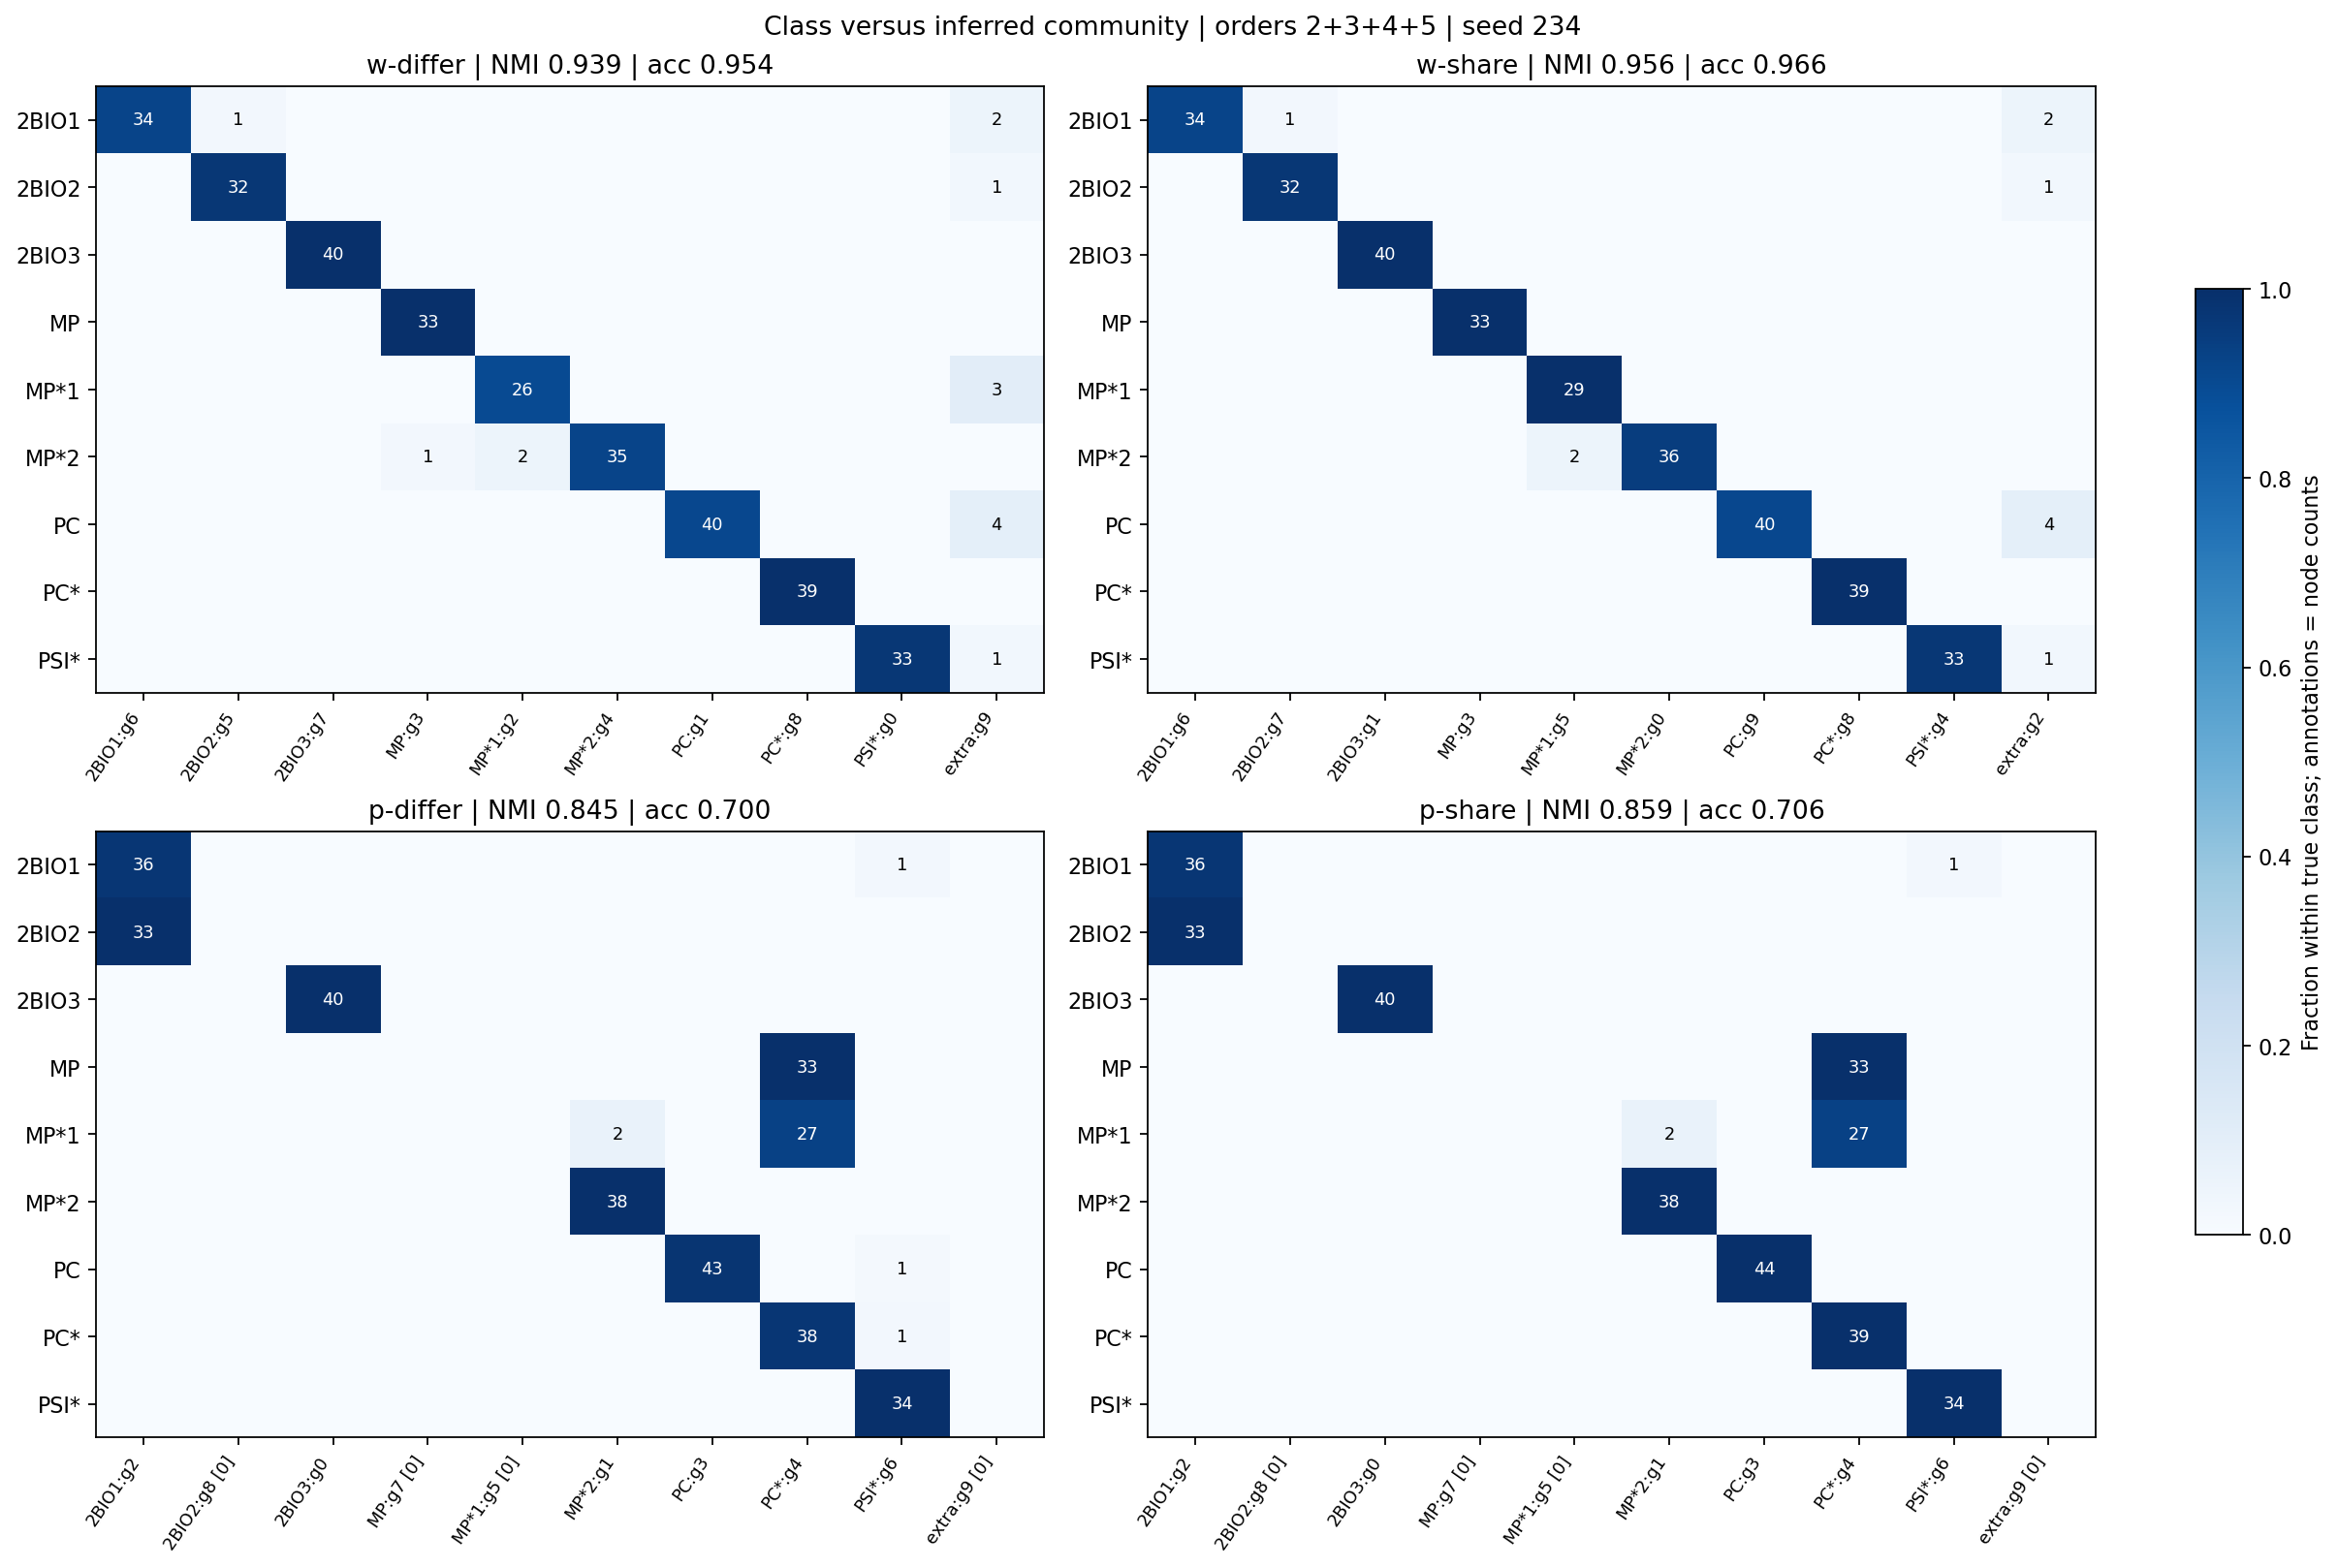

,mode,order_set,seed,N,K,plot_position,original_community,plot_label,n,hard_count,posterior_mean
70,w-differ,2+3+4+5,234,327,10,0,6,2BIO1:g6,1.039755e-01,34,1.039755e-01
71,w-differ,2+3+4+5,234,327,10,1,5,2BIO2:g5,1.009174e-01,33,1.009182e-01
72,w-differ,2+3+4+5,234,327,10,2,7,2BIO3:g7,1.223242e-01,40,1.223234e-01
73,w-differ,2+3+4+5,234,327,10,3,3,MP:g3,1.039755e-01,34,1.033775e-01
74,w-differ,2+3+4+5,234,327,10,4,2,MP*1:g2,8.562691e-02,28,8.584452e-02
75,w-differ,2+3+4+5,234,327,10,5,4,MP*2:g4,1.070336e-01,35,1.074279e-01
76,w-differ,2+3+4+5,234,327,10,6,1,PC:g1,1.223242e-01,40,1.223242e-01
77,w-differ,2+3+4+5,234,327,10,7,8,PC*:g8,1.192661e-01,39,1.192660e-01
78,w-differ,2+3+4+5,234,327,10,8,0,PSI*:g0,1.009174e-01,33,1.009195e-01
79,w-differ,2+3+4+5,234,327,10,9,9,extra:g9,3.363914e-02,11,3.362322e-02


In [22]:
# This display cell also works when the optional diagnostic export is disabled.
confusion_path = FULL_RESULT_DIR / f"class_confusion_{FULL_PLOT_SUFFIX}.png"
if not confusion_path.is_file():
    selected = [case for case in FULL_REPORT['cases']
                if tuple(case['orders']) == tuple(FULL_SHOW_ORDER_SET)
                and int(case['seed']) == int(FULL_SHOW_SEED)]
    if len(selected) != len(FULL_MODES):
        raise ValueError('The selected order set and seed must contain all four model fits.')
    confusion_figure = full_confusion_figure(selected)
    confusion_figure.savefig(confusion_path, dpi=160, bbox_inches='tight')
    confusion_figure.savefig(confusion_path.with_suffix('.pdf'), bbox_inches='tight')
    plt.close(confusion_figure)
full_show_saved_png(FULL_RESULT_DIR / f"class_confusion_{FULL_PLOT_SUFFIX}.png")
display(FULL_TABLES["community_alignment"].loc[
    (FULL_TABLES["community_alignment"]["order_set"] == "+".join(map(str, FULL_SHOW_ORDER_SET))) &
    (FULL_TABLES["community_alignment"]["seed"] == FULL_SHOW_SEED)])


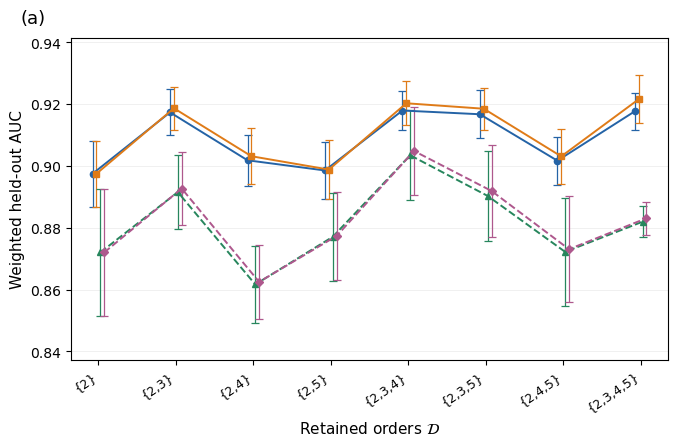

In [23]:
PAPER_AUC_FILES = paper_metric_plot(
    PAPER_DATA, "auc", PAPER_OUTPUT_DIR,
     show=PAPER_SHOW_FIGURES,
     show_legend=False,
     legend_loc=PAPER_LEGEND_LOC,
    legend_ncol=2,
    show_title=PAPER_SHOW_TITLES,
    show_axis_labels=PAPER_SHOW_AXIS_LABELS,
    panel_label="(a)" if PAPER_SHOW_PANEL_LABELS else None,
)

### 8.2 Standalone NMI: four curves and optional legend

Export `nmi_four_methods` with its legend inside the lower-right corner by default. `show_legend=False` hides it; `legend_loc` and `legend_ncol` set position and columns. `show_title` controls the figure title, `show_axis_labels` controls axis labels, and `panel_label=None` hides the panel letter. These controls also apply to aggregate AUC. Save captions as `_caption.txt` outside the figure.

NMI uses full-data fits; the current single-seed results have no error bars.

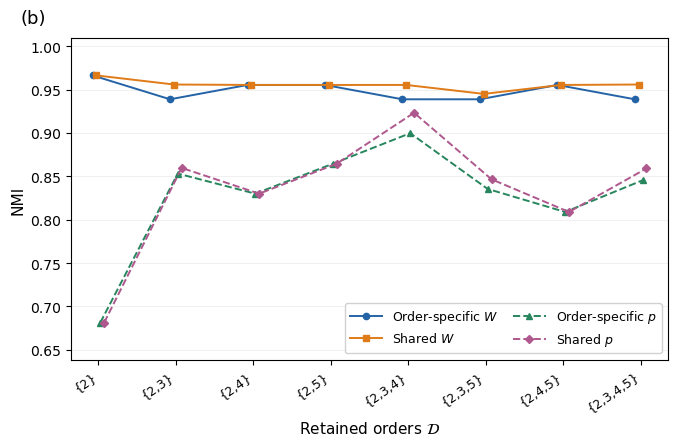

In [24]:
PAPER_NMI_FILES = paper_metric_plot(
    PAPER_DATA, "nmi", PAPER_OUTPUT_DIR,
    show=PAPER_SHOW_FIGURES,
    show_legend=PAPER_SHOW_LEGEND,
    legend_loc=PAPER_LEGEND_LOC,
    legend_ncol=2,
    show_title=PAPER_SHOW_TITLES,
    show_axis_labels=PAPER_SHOW_AXIS_LABELS,
    panel_label="(b)" if PAPER_SHOW_PANEL_LABELS else None,
)

### 8.3 Selected retained order sets: aggregate AUC and NMI

Report the candidate sets with the highest mean aggregate AUC and highest NMI separately. Also report full-data NMI for the AUC-selected set; the metrics come from different fits and evaluation procedures.
Use mean five-fold aggregate AUC without additional training. CSV files retain all tied sets; figures resolve display ties by fewer orders, then lexicographic order.

The two standalone table figures show method, selected order set, and score; CSV and LaTeX tables are also saved.

In [25]:
PAPER_SELECTION = paper_selected_order_table(PAPER_DATA, PAPER_OUTPUT_DIR)
display(PAPER_SELECTION)

,model,auc_selected_orders,cv_auc_mean,cv_auc_std,full_nmi_at_auc_selected_orders,nmi_selected_orders,full_nmi_max,auc_tied_order_sets,nmi_tied_order_sets
0,w-differ,"(2, 3, 4)",0.917901,0.006346,0.938831,"(2,)",0.966343,"{2,3,4}",{2}
1,w-share,"(2, 3, 4, 5)",0.921558,0.007698,0.955859,"(2,)",0.966343,"{2,3,4,5}",{2}
2,p-differ,"(2, 3, 4)",0.903424,0.014555,0.899756,"(2, 3, 4)",0.899756,"{2,3,4}","{2,3,4}"
3,p-share,"(2, 3, 4)",0.904802,0.014298,0.923270,"(2, 3, 4)",0.923270,"{2,3,4}","{2,3,4}"


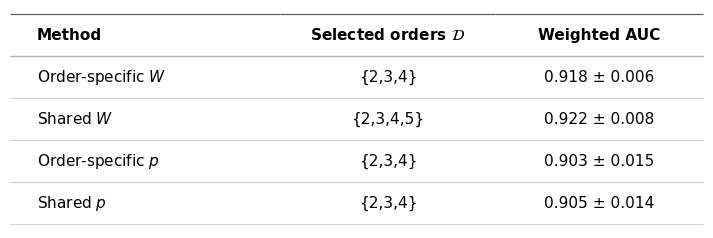

In [26]:
# Standalone table: highest aggregate-AUC order set and five-fold mean ± standard deviation.
PAPER_AUC_SELECTION_FILES = paper_selected_order_plot(
    PAPER_SELECTION, PAPER_DATA, "auc", PAPER_OUTPUT_DIR, show=PAPER_SHOW_FIGURES,
)

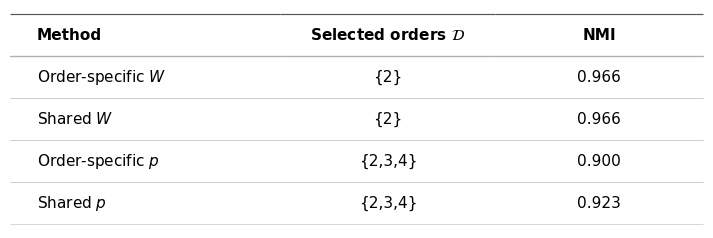

In [27]:
# Standalone table: highest-NMI order set and its NMI.
PAPER_NMI_SELECTION_FILES = paper_selected_order_plot(
    PAPER_SELECTION, PAPER_DATA, "nmi", PAPER_OUTPUT_DIR, show=PAPER_SHOW_FIGURES,
)

### 8.4 Paper heatmaps c and d: separate exports with one colorbar

Left panel c shows Order-specific W with class labels and no colorbar. Right panel d shows Shared W with a 0–1 colorbar and omits repeated class labels. Both use identical canvas and matrix dimensions for equal-width side-by-side layout. Retain all communities, including `Extra`.

`show_colorbar`, `show_class_labels`, `show_title`, and `show_axis_labels` control the corresponding elements; `panel_label=None` hides the letter and `annotate=False` hides cell numbers. Retain the original numeric format. Each p method also exports a complete standalone heatmap.

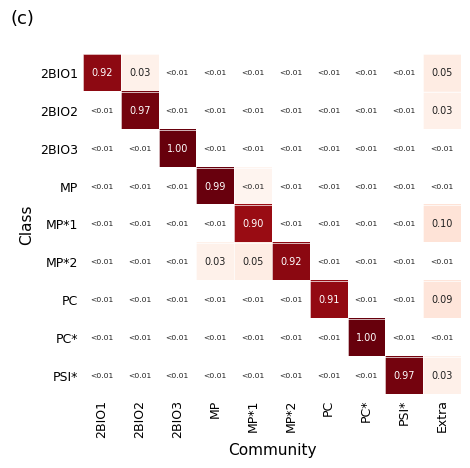

In [28]:
# Paper left panel (c): class labels, no colorbar.
PAPER_MEMBERSHIP_W_DIFFER_FILES = paper_membership_plot(
    FULL_REPORT["cases"], "w-differ", PAPER_MEMBERSHIP_ORDER_SET,
    PAPER_MEMBERSHIP_SEED, PAPER_OUTPUT_DIR, show=PAPER_SHOW_FIGURES,
    show_colorbar=False,
    show_class_labels=True,
    show_title=PAPER_SHOW_TITLES,
    show_axis_labels=PAPER_SHOW_AXIS_LABELS,
    panel_label="(c)" if PAPER_SHOW_PANEL_LABELS else None,
)

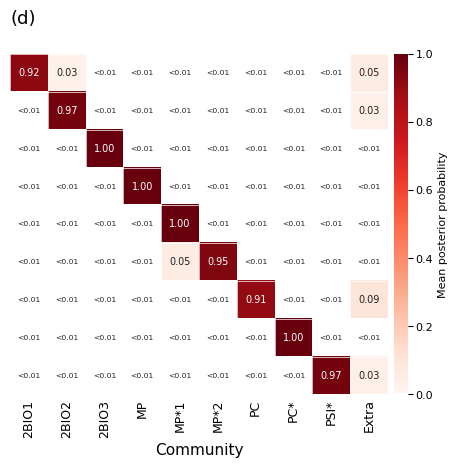

In [29]:
# Paper right panel (d): the shared colorbar, no repeated class labels.
PAPER_MEMBERSHIP_W_SHARE_FILES = paper_membership_plot(
    FULL_REPORT["cases"], "w-share", PAPER_MEMBERSHIP_ORDER_SET,
    PAPER_MEMBERSHIP_SEED, PAPER_OUTPUT_DIR, show=PAPER_SHOW_FIGURES,
    show_colorbar=PAPER_SHOW_COLORBAR,
    show_class_labels=False,
    show_title=PAPER_SHOW_TITLES,
    show_axis_labels=PAPER_SHOW_AXIS_LABELS,
    panel_label="(d)" if PAPER_SHOW_PANEL_LABELS else None,
)

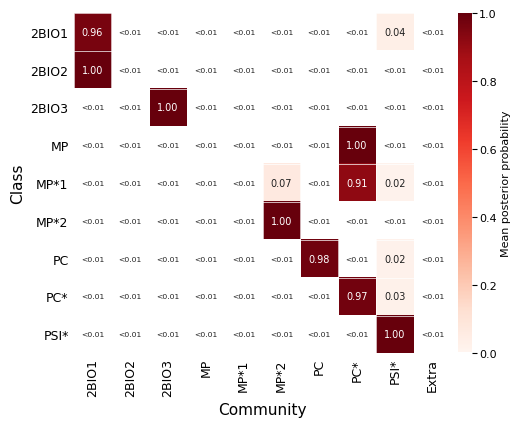

In [30]:
PAPER_MEMBERSHIP_P_DIFFER_FILES = paper_membership_plot(
    FULL_REPORT["cases"], "p-differ", PAPER_MEMBERSHIP_ORDER_SET,
    PAPER_MEMBERSHIP_SEED, PAPER_OUTPUT_DIR, show=PAPER_SHOW_FIGURES,
    show_colorbar=PAPER_SHOW_COLORBAR,
    show_class_labels=True,
    show_title=PAPER_SHOW_TITLES,
    show_axis_labels=PAPER_SHOW_AXIS_LABELS,
)

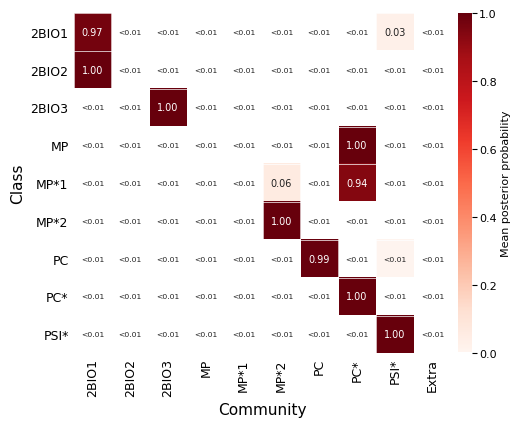

In [31]:
PAPER_MEMBERSHIP_P_SHARE_FILES = paper_membership_plot(
    FULL_REPORT["cases"], "p-share", PAPER_MEMBERSHIP_ORDER_SET,
    PAPER_MEMBERSHIP_SEED, PAPER_OUTPUT_DIR, show=PAPER_SHOW_FIGURES,
    show_colorbar=PAPER_SHOW_COLORBAR,
    show_class_labels=True,
    show_title=PAPER_SHOW_TITLES,
    show_axis_labels=PAPER_SHOW_AXIS_LABELS,
)

Each figure's `_caption.txt` defines its metrics; `_data.csv` retains plotted values. `selected_order_sets.csv` and `.tex` summarize the two selection criteria. Complete four-mode soft-posterior grids, affinity matrices, and AUCw tables remain in Sections 6–7.